In [1]:
import pandas as pd
import numpy as np
import os
import torch
import seaborn as sns
import random
import pickle
import matplotlib.gridspec as gridspec


from scipy.stats import pearsonr, spearmanr
from scipy.stats import rankdata
from matplotlib import pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve, auc


from Bio import pairwise2
from Bio.Seq import Seq
from Bio.Align import substitution_matrices
from Bio import SeqIO

from random import sample

from utils_for_analysis import (
    calculate_ss_for_df_and_factors,
    load_df_all,
    load_df_with_budget,
    discretized_parameter_scale,
    xlabel_dict,
    ylabel_dict,
    title_fontsize,
    label_fontsize,
    tick_fontsize,
    legend_fontsize,
    original_parameter_scale,
    color_map,
    fix_ticks,
    get_labels,
    positions,
    num_muts_column_name,
    DATASET_PATHS,
    plot_exporter
)


/home/labs/fleishman/itayta/.conda/envs/esm_env/lib/python3.10/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [145]:
export_plot = plot_exporter("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/library_screening")

In [3]:
calculate_from_scratch = False

# if not calculate_from_scratch:

#     strict_max_scores = "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/strict_revision_greedy_max_exploration_results.pkl"

In [4]:

def get_relevant_columns_gfp_protgym(df, first_col, last_col):
    si = np.where(df.columns == first_col)[0][0]
    ei = np.where(df.columns == last_col)[0][0]+1
    return df.columns[si:ei]

def nmt_relevant_columns(df):
    si = np.where(df.columns == "1")[0][0]
    ei = np.where(df.columns == "272")[0][0]+1
    positions_with_mutations =  np.array([len(pd.unique(df.iloc[:,i])) > 1 for i in range(si,ei)])
    return df.columns[si:ei][positions_with_mutations]

def get_relevant_columns(dataset, df):
    cols = get_relevant_columns_gfp_protgym(df, positions[dataset][0], positions[dataset][1])
    return cols



# --- OHE Feature Creation ---
def get_one_hot_encoding(sdf, relevant_columns):
    one_hot_encoding = pd.get_dummies(sdf[relevant_columns])
    return one_hot_encoding

datasets_and_activity = {
    "gcn4": {"path": "./data/gcn4/gcn4.csv", "activity_col": "activity"},
    "pard3": {"path": "./data/pard3/pard3.csv", "activity_col": "activity"},
    "pte": {"path": "./data/pte/pte.csv", "activity_col": "p-nitrophenyl_octanoate"},
    "nmt": {"path": "./data/nmt/nmt_full_seq.csv", "activity_col": "activity"},
    "lov": {"path": "./data/lov/lov.csv", "activity_col": "activity"},
    "gfp": {"path": "./data/gfp/gfp_dataset_10mut.csv", "activity_col": "inactive"},
    "aamyl": {"path": "./data/aamyl/aamyl.csv", "activity_col": "activity"},
    "trpb": {"path": "./data/trpb/trpb.csv", "activity_col": "activity"},
    "his2": {"path": "./data/his2/his2.csv", "activity_col": "activity"},
    "his5": {"path": "./data/his5/his5.csv", "activity_col": "activity"},
    "casp": {"path": "./data/casp/casp.csv", "activity_col": "activity"}
}

names_dict = {
    "esm2_t6_8M_UR50D": "ESM2 (8m)", 
    "esm2_t12_35M_UR50D": "ESM2 (35m)", 
    "esm2_t30_150M_UR50D": "ESM2 (150m)", 
    "esm2_t33_650M_UR50D" : "ESM2 (650m)",
    "pssm": "PSSM"
}



def get_best_worst_ranks(best, worst):
    """
    Given arrays or lists of best and worst scores,
    returns (ranks_best, ranks_worst) where each contains
    the rank (1 = highest) of each input element.
    """
    all_scores = np.array(list(best) + list(worst))
    # Higher score = higher rank, so negate for ranking function
    ranks = rankdata(-all_scores, method='average')
    ranks_best = ranks[:len(best)]
    ranks_worst = ranks[len(best):]
    return ranks_best, ranks_worst


import sys
os.chdir(os.path.join(os.getcwd(), "../code/"))
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from plm_base import *
plm_init(os.path.join(os.getcwd(), "../"))

os.chdir(os.path.join(os.getcwd(), "../notebooks"))



/home/labs/fleishman/itayta/.conda/envs/esm_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
def get_one_hot_encoding(sdf, relevant_columns):
    one_hot_encoding = pd.get_dummies(sdf[relevant_columns])
    return one_hot_encoding

In [6]:

def rank_with_ties(x, descending=True, method="min"):
    x = np.asarray(x)
    order = np.argsort(-x if descending else x)
    sorted_x = x[order]

    _, start, counts = np.unique(sorted_x, return_index=True, return_counts=True)

    ranks_sorted = np.empty(len(x), dtype=float)

    for s, c in zip(start, counts):
        ranks = np.arange(s + 1, s + c + 1)

        if method == "min":
            r = ranks.min()
        elif method == "max":
            r = ranks.max()
        elif method == "average":
            r = ranks.mean()
        elif method == "dense":
            r = np.where(start == s)[0][0] + 1
        else:
            raise ValueError("method must be 'min', 'max', 'average', or 'dense'")

        ranks_sorted[s:s + c] = r

    ranks_out = np.empty(len(x), dtype=float)
    ranks_out[order] = ranks_sorted

    return ranks_out

In [7]:
def sample_empirical_mutations(real_mutation_cols, pos_per_ohe_column, s, unique_mutations, rng):
    real_mutation_cols = np.asarray(real_mutation_cols)

    if not unique_mutations:
        if len(real_mutation_cols) < s:
            return None
        return rng.choice(real_mutation_cols, size=s, replace=False)

    chosen = []
    seen_positions = set()

    for col_idx in rng.permutation(real_mutation_cols):
        pos = pos_per_ohe_column[col_idx]

        if pos not in seen_positions:
            chosen.append(col_idx)
            seen_positions.add(pos)

        if len(chosen) == s:
            return np.asarray(chosen, dtype=int)

    return None


def get_candidate_library_fast(ohe, chosen_mutations, total_mutations, max_outside_muts=1):
    inside = ohe[:, chosen_mutations].sum(axis=1)
    outside = total_mutations - inside
    return np.flatnonzero((inside > 0) & (outside <= max_outside_muts))


def candidate_indices_from_inside(inside, total_mutations, max_outside_muts):
    outside = total_mutations - inside
    return np.flatnonzero((inside > 0) & (outside <= max_outside_muts))


def gof_vector(candidate_indices, activity, gof_threshold, k_values):
    p_gof = np.mean(activity[candidate_indices] > gof_threshold)
    return np.asarray(k_values, dtype=float) * p_gof


def median_activity_vector(candidate_indices, activity, k_values, n_subsamples, seed):
    candidate_activity = activity[candidate_indices]
    n_candidates = len(candidate_activity)

    rng = np.random.default_rng(seed)
    sampled = np.empty((n_subsamples, len(k_values)), dtype=float)

    for i in range(n_subsamples):
        shuffled = candidate_activity[rng.permutation(n_candidates)]

        for k_idx, k in enumerate(k_values):
            sampled[i, k_idx] = np.median(shuffled[:k])

    return np.median(sampled, axis=0)


def score_candidate_indices(
    candidate_indices,
    activity,
    gof_threshold,
    k_values,
    objective,
    n_subsamples,
    seed,
):
    if len(candidate_indices) < max(k_values):
        return -np.inf, None

    if objective == "gof":
        vec = gof_vector(candidate_indices, activity, gof_threshold, k_values)

    elif objective == "median_activity":
        vec = median_activity_vector(
            candidate_indices,
            activity,
            k_values,
            n_subsamples,
            seed,
        )

    else:
        raise ValueError("objective must be 'gof' or 'median_activity'")

    return float(np.sum(vec)), vec


def rank_mutations_for_seed(ohe, real_mutation_cols, activity, gof_threshold, objective):
    scores = np.full(len(real_mutation_cols), -np.inf, dtype=float)

    for i, col in enumerate(real_mutation_cols):
        idx = np.flatnonzero(ohe[:, col])

        if len(idx) == 0:
            continue

        if objective == "gof":
            scores[i] = np.mean(activity[idx] > gof_threshold)
        else:
            scores[i] = np.median(activity[idx])

    return np.asarray(real_mutation_cols)[np.argsort(-scores)]


def heuristic_seed(ranked_cols, pos_per_ohe_column, s, unique_mutations):
    if not unique_mutations:
        if len(ranked_cols) < s:
            return None
        return np.asarray(ranked_cols[:s], dtype=int)

    chosen = []
    seen_positions = set()

    for col in ranked_cols:
        pos = pos_per_ohe_column[col]

        if pos not in seen_positions:
            chosen.append(col)
            seen_positions.add(pos)

        if len(chosen) == s:
            return np.asarray(chosen, dtype=int)

    return None


In [8]:

def calc_pssm_matrices(
    pssm_score_per_mutation,
    actual_pos_per_ohe_col,
    activity,
    ohe,
    space_sizes,
    k_values,
    wt_idx,
    percentile=90,
    jaccard_threshold=0.8,
    max_hamming_distance=2,
    iters=30,
    unique_mutations=False,
    only_real_muts=True,
    strict=False,
):
    # Rank mutations by PSSM score (descending)
    pssm_rank = np.argsort(-pssm_score_per_mutation)

    muts_outside = 0 if strict else 1
    gof_threshold = np.percentile(activity, 90)
    #gof_threshold = 1
    gof_matrix = np.zeros((len(space_sizes), len(k_values)), dtype=int)
    mean_activity_matrix = np.zeros((len(space_sizes), len(k_values)), dtype=float)
    median_activity_matrix = np.zeros((len(space_sizes), len(k_values)), dtype=float)
    # best_gof_matrix = np.zeros((len(space_sizes), len(k_values)), dtype=int)
    # best_mean_activity_matrix = np.zeros((len(space_sizes), len(k_values)), dtype=float)
    # best_median_activity_matrix = np.zeros((len(space_sizes), len(k_values)), dtype=float)
    
    chosen_indices = {}
    metadata = {}

    for s_idx, s in enumerate(space_sizes):
        # Find indices of top N+1 unique mutations by PSSM score

        if unique_mutations:
            pssm_first_unique_indices = []
            seen = set()
            arr = np.array(actual_pos_per_ohe_col)[pssm_rank]
            for idx, val in enumerate(arr):                
                if only_real_muts and (ohe[wt_idx,pssm_rank[idx]] == 1):
                    continue

                if val not in seen:
                    pssm_first_unique_indices.append(idx)
                    seen.add(val)
                if len(pssm_first_unique_indices) == s:
                    break
            chosen_mutations_pssm = pssm_rank[pssm_first_unique_indices]    
            n_positions = s        
        else:
            n_positions = len(np.unique(actual_pos_per_ohe_col[s]))
            chosen_mutations_pssm = pssm_rank[:s]

        chosen_indices[s] = chosen_mutations_pssm
        

        overlap = ohe[:, chosen_mutations_pssm].sum(axis=1) / n_positions
        all_mut_idx_within_ohe = np.where(ohe[wt_idx,:].reshape(-1) == 0)[0]
        mutations_outside_library = ohe[:,all_mut_idx_within_ohe[~np.isin(all_mut_idx_within_ohe, chosen_mutations_pssm)]].sum(axis=1)

        # Criteria for being in library: must contain at least 1 mutant within the nominated library, but no more than 1 mutant
        # outside of it
        final_chosen_indices = np.where((overlap > 0) & (mutations_outside_library <= muts_outside))[0]

        ### OLD EXPERIMENTAL CODE
        # hamming_dist = (ohe[wt_idx,:].sum() - ohe @ ohe[wt_idx,:].T).reshape(-1)
        # final_chosen_indices = np.where((overlap > 0) & (hamming_dist > 1) & (hamming_dist <= (s +1)))[0]
        # # chosen_overlap = np.where(overlap > 0.8)[0]
        # # hamming_distance_among_chosen_overlap = (ohe[wt_idx,:].sum() - ohe @ ohe[wt_idx,:].T)[chosen_overlap]
        # # final_chosen_space = ((hamming_distance_among_chosen_overlap > 1) & (hamming_distance_among_chosen_overlap <= (s+2))).reshape(-1)
        # # final_chosen_indices = chosen_overlap[final_chosen_space]
        # ranking_of_chosen = np.argsort(-(rank_with_ties(hamming_dist[final_chosen_indices], descending=True) + 
        #                                  rank_with_ties(overlap[final_chosen_indices])))
        ###
        metadata[s] = {
            #"overlap": overlap,
            "chosen_overlap": overlap[final_chosen_indices],
            "muts_outside": mutations_outside_library[final_chosen_indices],
            "final_chosen_indices": final_chosen_indices,
            #"ranking_of_chosen": ranking_of_chosen
        }

        print("For S size (%d) (%s), max K is (%d), indices are %d" % (s, "Unique" if unique_mutations else "Non-unique", max(k_values), len(final_chosen_indices)))

        #continue
    
        # For each top-K
        for k_idx, k in enumerate(k_values):

            all_gof = []
            all_mean = []
            all_median = []

            
            if k >= len(final_chosen_indices):
                #print
                raise BaseException("got K(%d), get to assay from %d" % (k, len(final_chosen_indices)))
                gof_matrix[s_idx, k_idx] = -1
                mean_activity_matrix[s_idx, k_idx] = -1
                median_activity_matrix[s_idx, k_idx] = -1
                
            else:
                # best_activities_pssm = activity[final_chosen_indices[ranking_of_chosen[:k]]]
                # best_gof_matrix[s_idx, k_idx] = np.sum(best_activities_pssm > gof_threshold)
                # best_mean_activity_matrix[s_idx, k_idx] = np.mean(best_activities_pssm)
                # best_median_activity_matrix[s_idx, k_idx] = np.median(best_activities_pssm)

                for i in range(0, iters):
                    sampled_indices = np.random.choice(final_chosen_indices, size=k, replace=False)
                    activities_pssm = activity[sampled_indices]

                    all_gof.append(np.sum(activities_pssm > gof_threshold))
                    all_mean.append(np.mean(activities_pssm))
                    all_median.append(np.median(activities_pssm))

                gof_matrix[s_idx, k_idx] = np.mean(np.array(all_gof))
                mean_activity_matrix[s_idx, k_idx] = np.mean(np.array(all_mean))
                median_activity_matrix[s_idx, k_idx] = np.median(np.array(all_median))

### OLD VERSION

        # # Select N unique mutation columns, score each sequence by sum of their OHE columns
        # closest_to_pssm_space = np.argsort(
        #     -ohe[:, chosen_mutations_pssm].sum(axis=1)
        # )
        # # For each top-K
        # for k_idx, k in enumerate(k_values):
        #     activities_pssm = activity[closest_to_pssm_space[:k]]
        #     # Number of GOF (above upper 90th percentile)
        #     num_of_gof = np.sum(activities_pssm > gof_threshold)
        #     # Mean activity
        #     mean_activity = np.mean(activities_pssm)
        #     median_activity = np.median(activities_pssm)

        #     gof_matrix[s_idx, k_idx] = num_of_gof
        #     mean_activity_matrix[s_idx, k_idx] = mean_activity
        #     median_activity_matrix[s_idx, k_idx] = median_activity

    return gof_matrix, mean_activity_matrix, median_activity_matrix, chosen_indices, metadata

def get_top_worst_K_mutations_empirical(
    ohe,
    activity,
    K=5,
    plot=False
):
    mean_with_mutation_per_column = []
    mean_without_mutation_per_column = []
    for i in range(ohe.shape[1]):
        mean_val_with_mutation = np.mean(activity[np.where(ohe[:, i] == 1)[0]])
        mean_val_without_mutation = np.mean(activity[np.where(ohe[:, i] == 0)[0]])
        mean_with_mutation_per_column.append(mean_val_with_mutation/mean_val_without_mutation)
        mean_without_mutation_per_column.append(mean_val_without_mutation/mean_val_with_mutation)


    if plot:
        fig, axes = plt.subplots(1, 2, figsize=(6,3))

        axes[0].scatter(mean_without_mutation_per_column, mean_with_mutation_per_column)
        axes[0].set_xlabel("Mean without mutation")
        axes[0].set_ylabel("Mean with mutation")
        axes[0].set_title("With vs Without Mutation")

        ratio = np.array(mean_with_mutation_per_column) / np.array(mean_without_mutation_per_column)
        axes[1].hist(ratio, bins=20)
        axes[1].set_xlabel("With / Without Mutation Ratio")
        axes[1].set_ylabel("Frequency")
        axes[1].set_title("Distribution of Ratio")

        plt.tight_layout()
        plt.show()

    ratio = np.array(mean_with_mutation_per_column)/np.array(mean_without_mutation_per_column)
    worst_K_indices = np.argsort(ratio)[0:K]
    best_K_indices  = np.argsort(-ratio)[0:K]

    return (best_K_indices, worst_K_indices, ratio)


def run_model(
    pssm,
    ohe,
    ohe_columns,
    activity,
    vocab_col_idx_dict,
    k_values,
    wt_idx,
    space_sizes,
    plot=False,
    skip_library_gen=False,
    strict=False
):    

    best_K_empirical_indices, worst_K_empirical_indices, ratio = get_top_worst_K_mutations_empirical(
        ohe,
        activity,
        K=5,
        plot=plot
    )

    best_K_empirical_mutations = ohe_columns[best_K_empirical_indices]
    worst_K_empirical_mutations = ohe_columns[worst_K_empirical_indices]

    actual_pos_per_ohe_col = [int(col.split("_")[0][1:]) for col in ohe_columns] # PDB INDEX
    actual_vocab_per_ohe_col = [col.split("_")[-1] for col in ohe_columns] 
    pssm_score_per_mutation = []

    for p,v in zip(actual_pos_per_ohe_col, actual_vocab_per_ohe_col):
        col_idx = vocab_col_idx_dict[v]
        row_idx = p - 1 # IT SHOULD BE PDB IDX!!!!!!!!!!!
        pssm_score_per_mutation.append(pssm[row_idx,col_idx])

    pssm_score_per_mutation = np.array(pssm_score_per_mutation)

    pssm_scores_best = pssm_score_per_mutation[best_K_empirical_indices]
    pssm_scores_worst = pssm_score_per_mutation[worst_K_empirical_indices]

    # PSSM ranks
    ranks_best, ranks_worst = get_best_worst_ranks(
        pssm_scores_best, 
        pssm_scores_worst
    )

    if skip_library_gen:
        unique_gof_matrix = None
        unique_mean_activity_matrix = None
        unique_median_activity_matrix = None
        unique_chosen_indices = None
        unique_metadata = None
    else:
        unique_results = calc_pssm_matrices(
            pssm_score_per_mutation,
            actual_pos_per_ohe_col,
            activity,
            ohe,
            k_values=k_values,
            wt_idx=wt_idx,
            space_sizes=space_sizes,
            unique_mutations=True,
            strict=strict,
        )

        unique_gof_matrix, unique_mean_activity_matrix, unique_median_activity_matrix, unique_chosen_indices, unique_metadata = unique_results

    
    # non_unique_results = calc_pssm_matrices(
    #     pssm_score_per_mutation,
    #     actual_pos_per_ohe_col,
    #     activity,
    #     ohe,
    #     k_values=k_values,
    #     wt_idx=wt_idx,
    #     space_sizes=space_sizes,
    #     unique_mutations=False
    # )

    # non_unique_gof_matrix, non_unique_mean_activity_matrix, non_unique_median_activity_matrix, non_unique_chosen_indices, non_unique_metadata = non_unique_results
    empirical_vs_model_prob_spearmanr = spearmanr(ratio, pssm_score_per_mutation)

    results = {
        "empirical_vs_model_prob_spearmanr": empirical_vs_model_prob_spearmanr,
        "unique_gof_matrix": unique_gof_matrix,
        "unique_mean_activity_matrix": unique_mean_activity_matrix,
        "unique_median_activity_matrix": unique_median_activity_matrix,
        "unique_metadata": unique_metadata,
        "library_gen": skip_library_gen,
        # "non_unique_gof_matrix": non_unique_gof_matrix,
        # "non_unique_mean_activity_matrix": non_unique_mean_activity_matrix,
        # "non_unique_median_activity_matrix": non_unique_median_activity_matrix,
        # "non_unique_metadata" : non_unique_metadata,
        "ranks_best": ranks_best,
        "ranks_worst": ranks_worst,
        "empirical_vs_model_prob_spearmanr": empirical_vs_model_prob_spearmanr,
        "unique_chosen_indices": unique_chosen_indices,
        # "non_unique_chosen_indices": non_unique_chosen_indices,
    }

    return results


In [9]:

# Define desired dataset order
dataset_order = ["gcn4", "trpb", "his2", "his5", "casp", "aamyl", "gfp","pard3", "lov", "nmt", "pte"]
datasets_to_skip_lib_gen = ["pte", "nmt", "gcn4", "pard3"]

strict_sample_settings = {

    "gcn4": {
        "space_sizes": [],#[6,7],#,6,7,8,9,10,20],
        "k_values": [],#[5,8,10]#,100],
    },
    "pard3": {
        "space_sizes": [],#[6,7],#,6,7,8,9,10,20],
        "k_values": [],#[5,8,10,15,20],
    },
    
    "aamyl": {
        "space_sizes": [30,40,50],
        "k_values": [5,10,25]
    },
    "gfp": {
        "space_sizes": [6,7,8],
        "k_values": [5,10,25]
    },
    "his2": {
        "space_sizes": [6,7,8],
        "k_values": [5, 10, 25]
    },
    "his5": {
        "space_sizes": [6,7,8],
        "k_values": [5, 10, 25,]
    },
    "casp": {
        "space_sizes": [8,9,10],
        "k_values": [5, 8, 10]
    },    
    "trpb": {
        "space_sizes": [6,7,8,9,10,11,12],
        "k_values": [5,10,25]
    },
    "lov": {
        "space_sizes": [6,7,8],
        "k_values": [5,10,25]
    },
    "nmt": {
        "space_sizes": [],
        "k_values": []#, 10, 15, 20, 30, 40, 50]
    },
    "pte": {
        "space_sizes": [],
        "k_values": []
    }
}




sample_settings = {

    "gcn4": {
        "space_sizes": [],#[6,7],#,6,7,8,9,10,20],
        "k_values": [],#[5,8,10]#,100],
    },
    "pard3": {
        "space_sizes": [],#[6,7],#,6,7,8,9,10,20],
        "k_values": [],#[5,8,10,15,20],
    },
    
    "aamyl": {
        "space_sizes": [30,40,50],
        "k_values": [5,10,25,50]
    },
    "gfp": {
        "space_sizes": [3,4,5,6,7,8],
        "k_values": [5,10,25,50]
    },
    "his2": {
        "space_sizes": [3,4,5,6,7,8],
        "k_values": [5,10,25,50]
    },
    "his5": {
        "space_sizes": [3,4,5,6,7,8],
        "k_values": [5,10,25,50]
    },
    "casp": {
        "space_sizes": [3,4,5,6,7,8],
        "k_values": [5,10,25,50]
    },    
    "trpb": {
        "space_sizes": [3,4,5,6,7,8],
        "k_values": [5,10,25,50]
    },
    "lov": {
        "space_sizes": [3,4,5,6,7,8],
        "k_values": [5,10,25,50]
    },
    "nmt": {
        "space_sizes": [],
        "k_values": []#, 10, 15, 20, 30, 40, 50]
    },
    "pte": {
        "space_sizes": [],
        "k_values": []
    }
}

In [10]:

if calculate_from_scratch:
    overwrite = True
    hybridize = False
    strict = True
    result_file_name = "%srevision_all_results.pkl" % ("strict_" if strict else "")

    if os.path.exists(result_file_name) and not overwrite:
        with open(result_file_name, 'rb') as f:
            all_results = pickle.load(f)
    else:
        all_results = {}
        all_models = [
            "esm2_t6_8M_UR50D", 
            "esm2_t12_35M_UR50D", 
            "esm2_t30_150M_UR50D", 
            "esm2_t33_650M_UR50D"
        ]

        #all_results = {}

        for model_name in all_models:

            model = plmEmbeddingModel(
                            plm_name="%s" % model_name, 
                            logits_only=True, 
                            emb_only=False
                        ).eval()

            vocab = model.vocab
    
            work_sample = strict_sample_settings if strict else sample_settings
            work_datasets =  ["his2", "his5", "trpb", "aamyl", "gfp", "lov", "casp"]
            if not strict:
                work_datasets = work_datasets + datasets_to_skip_lib_gen
                    
            for dataset in work_datasets:    
                print("Runing datasets: %s (%s)" % (dataset, model_name))
                dataset_path = DATASET_PATHS[dataset]
                df = pd.read_csv(dataset_path)
                wt_idx = np.where(df["num_muts"] == 0)[0]
                wt_idx = np.flatnonzero(df["num_muts"].eq(0))
                assert len(wt_idx) == 1, f"Expected one WT row, found {len(wt_idx)}"
                wt_seq = df.iloc[wt_idx[0]]["full_seq"]

                all_tokens = model.encode("".join(vocab))
                wt_tokens = model.encode(wt_seq)
                all_tokens = all_tokens[1:-1]

                k_values = work_sample[dataset]["k_values"]
                space_sizes = work_sample[dataset]["space_sizes"]

                # get one-hot encoding for relevant columns
                relevant_columns = get_relevant_columns(dataset, df)
                ohe = get_one_hot_encoding(df, relevant_columns)
                ohe_columns = ohe.columns
                ohe = ohe.to_numpy().astype(int)
                assert ohe.shape[1] == sum([len(pd.unique(df[C])) for C in relevant_columns])

                activity_col = datasets_and_activity[dataset]["activity_col"]
                activity = df[activity_col].to_numpy()

                if dataset == "gfp":
                    activity = (~activity).astype(int)

                pssm = pd.read_csv(f"./data/{dataset}//pssm_scores.csv")
                vocab_col_idx_dict = dict((v,i) for i,v in enumerate(pssm.columns[1:]))

                np_pssm = pssm.iloc[:,1:].to_numpy()

                print("PSSM")
                pssm_results = run_model(
                    np_pssm, 
                    ohe,
                    ohe_columns,
                    activity,
                    vocab_col_idx_dict,
                    k_values,
                    wt_idx,
                    space_sizes,
                    plot=False,
                    skip_library_gen=dataset in datasets_to_skip_lib_gen
                )

                pssm_results["actual_pssm"] = pssm
                pssm_results["actual_np_pssm"] = np_pssm

                res_name = "%s_%s" % (dataset, "pssm")

                if res_name not in all_results:
                    all_results[res_name] = pssm_results

                logits_path = f"./data/{dataset}/%s_logits.np.npy" % model_name
                if os.path.exists(logits_path):
                    logits = np.load(logits_path)
                else:                
                    logits = model(torch.tensor(wt_tokens).unsqueeze(0))
                    logits = logits[0].softmax(dim=1)
                    logits = logits.detach().numpy()
                    np.save(logits_path, logits)

                model_logits = logits[1:-1,:] # Get rid

                rearranged_to_pssm_logits = []
                for vc in pssm.columns[1:]:
                    rearranged_to_pssm_logits.append(model_logits[:,np.where(np.array(vocab) == vc)[0]])

                model_like_pssm = np.concatenate(rearranged_to_pssm_logits, axis=1) 
                assert np_pssm.shape == model_like_pssm.shape

                plm_results = run_model(
                    model_like_pssm, 
                    ohe,
                    ohe_columns,
                    activity,
                    vocab_col_idx_dict,
                    k_values,
                    wt_idx,
                    space_sizes,
                    skip_library_gen=dataset in datasets_to_skip_lib_gen
                )

                plm_results["actual_pssm"] = model_logits
                plm_results["actual_np_pssm"] = model_like_pssm

                res_name = "%s_%s" % (dataset, model_name)
                all_results[res_name] = plm_results

                if hybridize:
                    hybrid_pssm = torch.from_numpy(np_pssm).to(torch.float32)
                    hybrid_pssm = hybrid_pssm.softmax(dim=1)
                    hybrid_pssm = hybrid_pssm.detach().numpy()
                    hybrid_pssm = model_like_pssm * hybrid_pssm

                    hybrid_results = run_model(
                        hybrid_pssm, 
                        ohe,
                        ohe_columns,
                        activity,
                        vocab_col_idx_dict,
                        k_values,
                        wt_idx,
                        space_sizes,
                        skip_library_gen=dataset in datasets_to_skip_lib_gen
                    )

                    hybrid_results["actual_pssm"] = hybrid_pssm
                    hybrid_results["actual_np_pssm"] = hybrid_pssm

                    res_name = "%s_hybrid_pssm_%s" % (dataset, model_name)
                    all_results[res_name] = hybrid_results

                print("Finsihed analyzing %s - %s" % (dataset, model_name))
                
        with open(result_file_name, 'wb') as f:
            pickle.dump(all_results, f)


In [11]:
if calculate_from_scratch:
    strict=False
    RESET_ALL = True
    FORCE_RERUN_DATASETS = set()  # e.g. {"trpb", "aamyl"}

    N_GREEDY_RESTARTS = 6
    MAX_GREEDY_ROUNDS = 12
    N_SWAP_TRIALS = 250

    N_TOP_ADD_CANDIDATES = 40
    N_COVERAGE_ADD_CANDIDATES = 40
    N_RANDOM_ADD_CANDIDATES = 40

    N_FINALISTS = 30
    SEARCH_N_SUBSAMPLES = 7
    FINAL_N_SUBSAMPLES = 500

    BASE_SEED = 0
    VERIFY_SAVE = True

    MAX_OUTSIDE_MUTS = 0 if strict else 1

    max_scores_path = (
        "strict_revision_greedy_max_exploration_results.pkl"
        if strict
        else "revision_greedy_max_exploration_results.pkl"
    )

    print("Saving to:", os.path.abspath(max_scores_path))

    def greedy_swap_maximum(
        ohe,
        real_mutation_cols,
        ranked_cols,
        coverage_ranked_cols,
        pos_per_ohe_column,
        total_mutations,
        activity,
        gof_threshold,
        k_values,
        s,
        unique_mutations,
        objective,
        max_outside_muts=1,
        n_restarts=6,
        max_rounds=12,
        n_swap_trials=250,
        n_top_add=40,
        n_coverage_add=40,
        n_random_add=40,
        n_finalists=30,
        search_n_subsamples=7,
        final_n_subsamples=500,
        seed=0,
    ):
        """
        Fixed-S greedy swap optimization.

        Search priority is feasibility first:

            1. If N < max(K), maximize N.
            2. Once N >= max(K), maximize the requested objective.

        Therefore sparse strict libraries can climb toward feasibility instead of
        immediately being rejected.
        """

        rng = np.random.default_rng(seed)
        real_mutation_cols = np.asarray(real_mutation_cols, dtype=int)
        max_k = max(k_values)

        search_cache = {}


        def score_library(mutations, candidate_indices=None):
            key = tuple(sorted(np.asarray(mutations, dtype=int)))

            if key in search_cache:
                return search_cache[key]

            if candidate_indices is None:
                candidate_indices = get_candidate_library_fast(
                    ohe,
                    np.asarray(key),
                    total_mutations,
                    max_outside_muts,
                )

            n_candidates = len(candidate_indices)

            # ---------------------------------------------------------------------
            # INFEASIBLE LIBRARY
            # ---------------------------------------------------------------------

            if n_candidates < max_k:
                # Any feasible library beats any infeasible library.
                # Among infeasible libraries, higher coverage wins.
                result = ((0, n_candidates), -np.inf, None, n_candidates)

            # ---------------------------------------------------------------------
            # FEASIBLE LIBRARY
            # ---------------------------------------------------------------------

            else:
                score, vec = score_candidate_indices(
                    candidate_indices,
                    activity,
                    gof_threshold,
                    k_values,
                    objective,
                    search_n_subsamples,
                    seed + 1000,
                )

                result = ((1, score), score, vec, n_candidates)

            search_cache[key] = result
            return result


        # =========================================================================
        # MULTIPLE RESTARTS
        # =========================================================================

        for restart in range(n_restarts):

            # ---------------------------------------------------------------------
            # INITIAL SEED
            # ---------------------------------------------------------------------

            if restart == 0:
                # Seed using empirically promising mutations.
                current = heuristic_seed(
                    ranked_cols,
                    pos_per_ohe_column,
                    s,
                    unique_mutations,
                )

            elif restart == 1:
                # Seed using highly represented mutations to help obtain coverage.
                current = heuristic_seed(
                    coverage_ranked_cols,
                    pos_per_ohe_column,
                    s,
                    unique_mutations,
                )

            else:
                # Random restart.
                current = sample_empirical_mutations(
                    real_mutation_cols,
                    pos_per_ohe_column,
                    s,
                    unique_mutations,
                    rng,
                )


            if current is None:
                print(f"  {objective} restart {restart + 1}: could not construct S={s} seed")
                continue


            current_priority, current_score, _, current_n = score_library(current)

            # Current number of nominated mutations carried by every variant.
            current_inside = ohe[:, current].sum(axis=1).astype(np.int16, copy=False)


            # =====================================================================
            # GREEDY ROUNDS
            # =====================================================================

            for round_idx in range(max_rounds):

                current_set = set(map(int, current))

                available = np.asarray(
                    [c for c in real_mutation_cols if int(c) not in current_set],
                    dtype=int,
                )

                # -----------------------------------------------------------------
                # CANDIDATE MUTATIONS TO ADD
                # -----------------------------------------------------------------

                top_adds = [
                    c for c in ranked_cols
                    if int(c) not in current_set
                ][:n_top_add]

                coverage_adds = [
                    c for c in coverage_ranked_cols
                    if int(c) not in current_set
                ][:n_coverage_add]

                n_random = min(n_random_add, len(available))

                if n_random:
                    random_adds = rng.choice(available, size=n_random, replace=False)
                else:
                    random_adds = np.array([], dtype=int)

                add_pool = np.unique(
                    np.concatenate([
                        np.asarray(top_adds, dtype=int),
                        np.asarray(coverage_adds, dtype=int),
                        random_adds,
                    ])
                ).astype(int)


                # -----------------------------------------------------------------
                # GENERATE ONE-MUTATION SWAPS
                # -----------------------------------------------------------------

                proposals = []
                current_positions = pos_per_ohe_column[current]

                for remove_idx in range(s):

                    if unique_mutations:
                        other_positions = set(np.delete(current_positions, remove_idx))
                    else:
                        other_positions = None

                    for add_col in add_pool:

                        if unique_mutations and pos_per_ohe_column[add_col] in other_positions:
                            continue

                        proposals.append((remove_idx, int(add_col)))


                if not proposals:
                    break


                # Limit number of evaluated swaps per round.
                if len(proposals) > n_swap_trials:
                    keep = rng.choice(len(proposals), size=n_swap_trials, replace=False)
                    proposals = [proposals[i] for i in keep]


                # -----------------------------------------------------------------
                # FIND BEST IMPROVING SWAP
                # -----------------------------------------------------------------

                best_priority = current_priority
                best_proposal = None
                best_score = current_score
                best_n = current_n


                for remove_idx, add_col in proposals:

                    remove_col = int(current[remove_idx])

                    proposal = current.copy()
                    proposal[remove_idx] = add_col

                    key = tuple(sorted(map(int, proposal)))


                    if key in search_cache:
                        priority, score, _, n_candidates = search_cache[key]

                    else:
                        # Incremental update instead of summing all S columns again.
                        proposal_inside = current_inside - ohe[:, remove_col] + ohe[:, add_col]

                        candidate_indices = candidate_indices_from_inside(
                            proposal_inside,
                            total_mutations,
                            max_outside_muts,
                        )

                        priority, score, _, n_candidates = score_library(
                            proposal,
                            candidate_indices,
                        )


                    if priority > best_priority:
                        best_priority = priority
                        best_score = score
                        best_n = n_candidates
                        best_proposal = (remove_idx, remove_col, add_col)


                # -----------------------------------------------------------------
                # LOCAL OPTIMUM
                # -----------------------------------------------------------------

                if best_proposal is None:
                    break


                remove_idx, remove_col, add_col = best_proposal

                current[remove_idx] = add_col
                current_inside = current_inside - ohe[:, remove_col] + ohe[:, add_col]

                current_priority = best_priority
                current_score = best_score
                current_n = best_n


            # =====================================================================
            # RESTART SUMMARY
            # =====================================================================

            if current_n >= max_k:
                print(
                    f"  {objective:15s} restart {restart + 1}/{n_restarts}: "
                    f"search={current_score:.6g}, N={current_n}"
                )

            else:
                print(
                    f"  {objective:15s} restart {restart + 1}/{n_restarts}: "
                    f"infeasible, N={current_n}/{max_k}"
                )


        # =========================================================================
        # COLLECT ALL FEASIBLE LIBRARIES VISITED DURING SEARCH
        # =========================================================================

        valid = [
            (key, value)
            for key, value in search_cache.items()
            if value[3] >= max_k and np.isfinite(value[1])
        ]


        if not valid:
            best_n = max((value[3] for value in search_cache.values()), default=0)

            print(
                f"  FINAL {objective:15s}: no feasible S={s} library found; "
                f"best coverage N={best_n}/{max_k}"
            )

            return None


        # Sort by cheap search score from best to worst.
        valid.sort(key=lambda item: item[1][1], reverse=True)

        # =========================================================================
        # BEST + EXEMPLARY WORST FINALIST REEVALUATION
        # =========================================================================

        # GOF is exact, so only one candidate at each extreme needs reevaluation.
        # Median activity is noisy, so reevaluate several candidates from both ends.
        if objective == "median_activity":
            n_keep = min(n_finalists, len(valid))
            best_finalists = valid[:n_keep]
            worst_finalists = valid[-n_keep:]
        else:
            best_finalists = valid[:1]
            worst_finalists = valid[-1:]

        def reevaluate_finalists(finalists, choose="max", seed_offset=0):
            selected = None

            for rank, (key, (_, search_score, _, _)) in enumerate(finalists):
                mutations = np.asarray(key, dtype=int)
                candidate_indices = get_candidate_library_fast(
                    ohe, mutations, total_mutations, max_outside_muts
                )

                if objective == "gof":
                    final_vec = gof_vector(candidate_indices, activity, gof_threshold, k_values)
                else:
                    final_vec = median_activity_vector(
                        candidate_indices, activity, k_values, final_n_subsamples,
                        seed + seed_offset + rank
                    )

                final_score = float(np.sum(final_vec))
                result = {
                    "mutations": mutations,
                    "values": final_vec,
                    "score": final_score,
                    "search_score": search_score,
                    "n_candidates": len(candidate_indices),
                    "finalist_rank": rank + 1,
                }

                if selected is None:
                    selected = result
                elif choose == "max" and final_score > selected["score"]:
                    selected = result
                elif choose == "min" and final_score < selected["score"]:
                    selected = result

            return selected

        best_final = reevaluate_finalists(best_finalists, choose="max", seed_offset=10_000_000)
        worst_final = reevaluate_finalists(worst_finalists, choose="min", seed_offset=20_000_000)

        best_final["n_evaluated_libraries"] = len(search_cache)
        best_final["worst_mutations"] = worst_final["mutations"]
        best_final["worst_values"] = worst_final["values"]
        best_final["worst_score"] = worst_final["score"]
        best_final["worst_search_score"] = worst_final["search_score"]
        best_final["worst_n_candidates"] = worst_final["n_candidates"]

        print(
            f"  FINAL {objective:15s}: search={best_final['search_score']:.6g}, "
            f"final={best_final['score']:.6g}, N={best_final['n_candidates']}, "
            f"values={np.round(best_final['values'], 6)}"
        )
        print(
            f"  WORST {objective:15s}: search={worst_final['search_score']:.6g}, "
            f"final={worst_final['score']:.6g}, N={worst_final['n_candidates']}, "
            f"values={np.round(worst_final['values'], 6)}"
        )

        return best_final


    # =============================================================================
    # LOAD EXISTING RESULTS
    # =============================================================================

    if os.path.exists(max_scores_path) and not RESET_ALL:
        with open(max_scores_path, "rb") as f:
            max_scores = pickle.load(f)

        print("Loaded existing datasets:", list(max_scores.keys()))

    else:
        max_scores = {}


    work_sample = strict_sample_settings if strict else sample_settings


    # =============================================================================
    # DATASET LOOP
    # =============================================================================

    for dataset_idx, dataset in enumerate(dataset_order):

        # =========================================================================
        # SKIPPING / FORCE RERUN
        # =========================================================================

        if dataset in datasets_to_skip_lib_gen and dataset not in FORCE_RERUN_DATASETS:
            print(f"Skipping {dataset}: listed in datasets_to_skip_lib_gen")
            continue


        if dataset in max_scores and dataset not in FORCE_RERUN_DATASETS:
            print(f"Skipping {dataset}: already exists")
            continue


        if dataset in FORCE_RERUN_DATASETS:
            print(f"\nForcing rerun of {dataset}")


        print(f"\n======= Processing {dataset} =======")


        # =========================================================================
        # DATASET SETTINGS
        # =========================================================================

        space_sizes = list(work_sample[dataset]["space_sizes"])
        k_values = list(work_sample[dataset]["k_values"])


        if not space_sizes or not k_values:
            print(f"Skipping {dataset}: empty space_sizes or k_values")
            continue


        # =========================================================================
        # LOAD DATA
        # =========================================================================

        df = pd.read_csv(DATASET_PATHS[dataset])

        relevant_columns = get_relevant_columns(dataset, df)

        ohe_df = get_one_hot_encoding(df, relevant_columns)
        ohe_columns = ohe_df.columns
        ohe = ohe_df.to_numpy().astype(np.int8)

        pos_per_ohe_column = np.asarray([
            int(col.split("_")[0][1:])
            for col in ohe_columns
        ])

        activity = df[datasets_and_activity[dataset]["activity_col"]].to_numpy()


        if dataset == "gfp":
            activity = (~activity).astype(int)


        # =========================================================================
        # WT
        # =========================================================================

        wt_rows = np.where(df["num_muts"].to_numpy() == 0)[0]


        if len(wt_rows) != 1:
            raise ValueError(
                f"{dataset}: expected exactly one WT row, found {len(wt_rows)}"
            )


        wt_idx = int(wt_rows[0])


        # =========================================================================
        # PRECOMPUTE DATASET-LEVEL QUANTITIES
        # =========================================================================

        real_mutation_cols = np.where(ohe[wt_idx] == 0)[0]

        total_mutations = ohe[:, real_mutation_cols].sum(axis=1)

        gof_threshold = np.percentile(activity, 90)


        print(
            f"Variants: {len(df)}, mutation columns: {len(real_mutation_cols)}, "
            f"max K: {max(k_values)}"
        )


        # =========================================================================
        # MUTATION RANKINGS USED TO GUIDE SEARCH
        # =========================================================================

        gof_ranked_cols = rank_mutations_for_seed(
            ohe,
            real_mutation_cols,
            activity,
            gof_threshold,
            "gof",
        )

        activity_ranked_cols = rank_mutations_for_seed(
            ohe,
            real_mutation_cols,
            activity,
            gof_threshold,
            "median_activity",
        )

        # Mutations that occur frequently in measured variants are useful for
        # reaching feasible library sizes, particularly under strict outside=0.
        mutation_support = ohe[:, real_mutation_cols].sum(axis=0)

        coverage_ranked_cols = real_mutation_cols[
            np.argsort(-mutation_support)
        ]


        # =========================================================================
        # OUTPUT MATRICES
        # =========================================================================

        shape = (len(space_sizes), len(k_values))

        unique_max_matrix_gof = np.full(shape, np.nan)
        unique_max_matrix_activity = np.full(shape, np.nan)

        non_unique_max_matrix_gof = np.full(shape, np.nan)
        non_unique_max_matrix_activity = np.full(shape, np.nan)


        # =========================================================================
        # WINNING MUTATION SETS
        # =========================================================================

        best_sampled_muts_unique_gof = {}
        best_sampled_muts_unique_activity = {}

        best_sampled_muts_non_unique_gof = {}
        best_sampled_muts_non_unique_activity = {}

        # Exemplary worst feasible libraries encountered during greedy search.
        worst_sampled_muts_unique_gof = {}
        worst_sampled_muts_unique_activity = {}
        worst_sampled_muts_non_unique_gof = {}
        worst_sampled_muts_non_unique_activity = {}

        # Human-readable OHE labels for the same worst mutation sets.
        worst_sampled_muts_unique_gof_labels = {}
        worst_sampled_muts_unique_activity_labels = {}
        worst_sampled_muts_non_unique_gof_labels = {}
        worst_sampled_muts_non_unique_activity_labels = {}


        best_library_size_unique_gof = {}
        best_library_size_unique_activity = {}

        best_library_size_non_unique_gof = {}
        best_library_size_non_unique_activity = {}


        greedy_metadata = {}


        # =========================================================================
        # SEARCH EACH S
        # =========================================================================

        for s_idx, s in enumerate(space_sizes):

            print(f"\n--- S={s} ---")


            seed_base = BASE_SEED + dataset_idx * 1_000_000 + s_idx * 10_000


            jobs = [
                ("unique_gof", True, "gof", gof_ranked_cols, seed_base + 1),
                ("unique_activity", True, "median_activity", activity_ranked_cols, seed_base + 2),
                ("non_unique_gof", False, "gof", gof_ranked_cols, seed_base + 3),
                ("non_unique_activity", False, "median_activity", activity_ranked_cols, seed_base + 4),
            ]


            s_meta = {}


            for name, unique, objective, ranked_cols, job_seed in jobs:

                result = greedy_swap_maximum(
                    ohe=ohe,
                    real_mutation_cols=real_mutation_cols,
                    ranked_cols=ranked_cols,
                    coverage_ranked_cols=coverage_ranked_cols,
                    pos_per_ohe_column=pos_per_ohe_column,
                    total_mutations=total_mutations,
                    activity=activity,
                    gof_threshold=gof_threshold,
                    k_values=k_values,
                    s=s,
                    unique_mutations=unique,
                    objective=objective,
                    max_outside_muts=MAX_OUTSIDE_MUTS,
                    n_restarts=N_GREEDY_RESTARTS,
                    max_rounds=MAX_GREEDY_ROUNDS,
                    n_swap_trials=N_SWAP_TRIALS,
                    n_top_add=N_TOP_ADD_CANDIDATES,
                    n_coverage_add=N_COVERAGE_ADD_CANDIDATES,
                    n_random_add=N_RANDOM_ADD_CANDIDATES,
                    n_finalists=N_FINALISTS,
                    search_n_subsamples=SEARCH_N_SUBSAMPLES,
                    final_n_subsamples=FINAL_N_SUBSAMPLES,
                    seed=job_seed,
                )


                s_meta[name] = result


                if result is None:
                    continue


                if name == "unique_gof":
                    unique_max_matrix_gof[s_idx] = result["values"]
                    best_sampled_muts_unique_gof[s] = result["mutations"]
                    best_library_size_unique_gof[s] = result["n_candidates"]
                    worst_sampled_muts_unique_gof[s] = result["worst_mutations"]
                    worst_sampled_muts_unique_gof_labels[s] = np.asarray(ohe_columns)[result["worst_mutations"]].tolist()

                elif name == "unique_activity":
                    unique_max_matrix_activity[s_idx] = result["values"]
                    best_sampled_muts_unique_activity[s] = result["mutations"]
                    best_library_size_unique_activity[s] = result["n_candidates"]
                    worst_sampled_muts_unique_activity[s] = result["worst_mutations"]
                    worst_sampled_muts_unique_activity_labels[s] = np.asarray(ohe_columns)[result["worst_mutations"]].tolist()

                elif name == "non_unique_gof":
                    non_unique_max_matrix_gof[s_idx] = result["values"]
                    best_sampled_muts_non_unique_gof[s] = result["mutations"]
                    best_library_size_non_unique_gof[s] = result["n_candidates"]
                    worst_sampled_muts_non_unique_gof[s] = result["worst_mutations"]
                    worst_sampled_muts_non_unique_gof_labels[s] = np.asarray(ohe_columns)[result["worst_mutations"]].tolist()

                elif name == "non_unique_activity":
                    non_unique_max_matrix_activity[s_idx] = result["values"]
                    best_sampled_muts_non_unique_activity[s] = result["mutations"]
                    best_library_size_non_unique_activity[s] = result["n_candidates"]
                    worst_sampled_muts_non_unique_activity[s] = result["worst_mutations"]
                    worst_sampled_muts_non_unique_activity_labels[s] = np.asarray(ohe_columns)[result["worst_mutations"]].tolist()


            greedy_metadata[s] = s_meta


        # =========================================================================
        # SAVE DATASET RESULTS
        # =========================================================================

        results = {
            "unique_gof_matrix": unique_max_matrix_gof,
            "unique_activity_matrix": unique_max_matrix_activity,

            "non_unique_gof_matrix": non_unique_max_matrix_gof,
            "non_unique_activity_matrix": non_unique_max_matrix_activity,

            "best_sampled_muts_unique_gof": best_sampled_muts_unique_gof,
            "best_sampled_muts_unique_activity": best_sampled_muts_unique_activity,

            "best_sampled_muts_non_unique_gof": best_sampled_muts_non_unique_gof,
            "best_sampled_muts_non_unique_activity": best_sampled_muts_non_unique_activity,

            "worst_sampled_muts_unique_gof": worst_sampled_muts_unique_gof,
            "worst_sampled_muts_unique_activity": worst_sampled_muts_unique_activity,
            "worst_sampled_muts_non_unique_gof": worst_sampled_muts_non_unique_gof,
            "worst_sampled_muts_non_unique_activity": worst_sampled_muts_non_unique_activity,

            "worst_sampled_muts_unique_gof_labels": worst_sampled_muts_unique_gof_labels,
            "worst_sampled_muts_unique_activity_labels": worst_sampled_muts_unique_activity_labels,
            "worst_sampled_muts_non_unique_gof_labels": worst_sampled_muts_non_unique_gof_labels,
            "worst_sampled_muts_non_unique_activity_labels": worst_sampled_muts_non_unique_activity_labels,

            "best_library_size_unique_gof": best_library_size_unique_gof,
            "best_library_size_unique_activity": best_library_size_unique_activity,

            "best_library_size_non_unique_gof": best_library_size_non_unique_gof,
            "best_library_size_non_unique_activity": best_library_size_non_unique_activity,

            "greedy_metadata": greedy_metadata,

            "search_method": "greedy_swap_v3_feasibility_first",
            "worst_library_definition": "lowest-scoring feasible library encountered during greedy search",
            "max_outside_muts": MAX_OUTSIDE_MUTS,

            "n_greedy_restarts": N_GREEDY_RESTARTS,
            "max_greedy_rounds": MAX_GREEDY_ROUNDS,
            "n_swap_trials": N_SWAP_TRIALS,

            "n_top_add_candidates": N_TOP_ADD_CANDIDATES,
            "n_coverage_add_candidates": N_COVERAGE_ADD_CANDIDATES,
            "n_random_add_candidates": N_RANDOM_ADD_CANDIDATES,

            "n_finalists": N_FINALISTS,

            "search_n_subsamples": SEARCH_N_SUBSAMPLES,
            "final_n_subsamples": FINAL_N_SUBSAMPLES,
        }


        max_scores[dataset] = results


        with open(max_scores_path, "wb") as f:
            pickle.dump(max_scores, f)


        # =========================================================================
        # VERIFY SAVED PICKLE
        # =========================================================================

        if VERIFY_SAVE:

            with open(max_scores_path, "rb") as f:
                check_scores = pickle.load(f)


            keys_to_check = [
                "unique_gof_matrix",
                "unique_activity_matrix",
                "non_unique_gof_matrix",
                "non_unique_activity_matrix",
            ]


            for key in keys_to_check:

                if not np.allclose(
                    check_scores[dataset][key],
                    results[key],
                    equal_nan=True,
                ):
                    raise RuntimeError(
                        f"Save verification failed for {dataset}/{key}"
                    )


            print(f"Verified saved matrices for {dataset}")


        print(f"Finished {dataset} and saved checkpoint")

In [ ]:
def plot_fraction_of_empirical_max(
    all_results,
    max_scores,
    sample_settings,
    mode="unique_gof",
    dataset_order=None,
    model_order=None,
    names_dict=None,
    dataset_names=None,                 # special dataset display names
    figsize=(14, 4),
    text_size=9,
    showfliers=False,
    ylim=None,
    log_y=False,
    plot_type="bar",                    # "box" or "bar"
    bar_center="median",                # "median" or "mean"
    bar_error="sd",                     # "sd" or None
    normalize_by_max=True,
    show_dataset_center_summary=True,
    summary_plot_type="dot",            # "dot" or "box"
    summary_gap=0.8,
    annotate_dataset=None,              # e.g. "trpb"
    annotate_model=None,                # e.g. "pssm"
    annotate_decimals=3,
):
    """
    Plot raw model performance or performance normalized by the empirical maximum.

    Main dataset plot
    -----------------
    plot_type="bar":
        Each dataset/model bar is either the mean or median across its S x K values,
        controlled explicitly by bar_center.

        If bar_error="sd", SD is shown upward only.

    plot_type="box":
        Show the full S x K distribution for each dataset/model.

    Across-datasets summary
    -----------------------
    First calculate one center per dataset/model using bar_center.

    summary_plot_type="dot":
        For each model, show the mean ± SD of those dataset-level centers.

    summary_plot_type="box":
        Show their distribution across datasets as a boxplot.

    Dataset labels
    --------------
    All dataset x tick labels are uppercased by default.

    dataset_names can override special cases, for example:
        {
            "his2": "HIS(2)",
            "his5": "HIS(5)",
            "casp": "AAV",
        }

    Debug annotation
    ----------------
    annotate_dataset and annotate_model select one dataset/model bar. The plotted
    value is written above the bar and the underlying raw values, mean, median,
    SD, and selected center are printed.
    """

    mode_settings = {
        "unique_gof": {
            "model_keys": ["unique_gof_matrix"],
            "max_keys": ["unique_gof_matrix"],
            "raw_ylabel": "GOF",
            "normalized_ylabel": "Fraction of empirical maximum GOF",
        },
        "unique_median": {
            "model_keys": ["unique_median_activity_matrix", "unique_activity_matrix"],
            "max_keys": ["unique_activity_matrix", "unique_median_activity_matrix"],
            "raw_ylabel": "Median activity",
            "normalized_ylabel": "Fraction of empirical maximum median activity",
        },
        "non_unique_gof": {
            "model_keys": ["non_unique_gof_matrix"],
            "max_keys": ["non_unique_gof_matrix"],
            "raw_ylabel": "GOF",
            "normalized_ylabel": "Fraction of empirical maximum GOF",
        },
        "non_unique_median": {
            "model_keys": ["non_unique_median_activity_matrix", "non_unique_activity_matrix"],
            "max_keys": ["non_unique_activity_matrix", "non_unique_median_activity_matrix"],
            "raw_ylabel": "Median activity",
            "normalized_ylabel": "Fraction of empirical maximum median activity",
        },
    }

    if mode not in mode_settings:
        raise ValueError(f"mode must be one of {list(mode_settings)}")

    if plot_type not in ["box", "bar"]:
        raise ValueError("plot_type must be 'box' or 'bar'")

    if bar_center not in ["median", "mean"]:
        raise ValueError("bar_center must be 'median' or 'mean'")

    if bar_error not in ["sd", None]:
        raise ValueError("bar_error must be 'sd' or None")

    if summary_plot_type not in ["dot", "box"]:
        raise ValueError("summary_plot_type must be 'dot' or 'box'")

    settings = mode_settings[mode]

    if names_dict is None:
        names_dict = {}

    if dataset_names is None:
        dataset_names = {}

    def find_key(d, possible_keys):
        return next((key for key in possible_keys if key in d and d[key] is not None), None)

    def get_dataset_label(dataset):
        return dataset_names.get(dataset, dataset.upper())

    # =========================================================================
    # DETERMINE DATASETS
    # =========================================================================

    available_datasets = [
        dataset for dataset in sample_settings
        if any(key.startswith(dataset + "_") for key in all_results)
    ]

    if dataset_order is None:
        datasets = available_datasets
    else:
        datasets = [d for d in dataset_order if d in available_datasets]

    if normalize_by_max:
        datasets = [d for d in datasets if d in max_scores]

    # =========================================================================
    # BUILD LONG-FORM DATAFRAME
    # =========================================================================

    rows = []

    for dataset in datasets:
        space_sizes = list(sample_settings[dataset]["space_sizes"])
        k_values = list(sample_settings[dataset]["k_values"])
        expected_shape = (len(space_sizes), len(k_values))

        if normalize_by_max:
            max_key = find_key(max_scores[dataset], settings["max_keys"])

            if max_key is None:
                print(f"Skipping {dataset}: no maximum matrix found for {mode}")
                continue

            max_matrix = np.asarray(max_scores[dataset][max_key])

            if max_matrix.shape != expected_shape:
                print(f"Skipping {dataset}: max matrix shape {max_matrix.shape} != expected {expected_shape}")
                continue

        else:
            max_matrix = None

        prefix = dataset + "_"
        dataset_model_keys = [key for key in all_results if key.startswith(prefix)]

        for result_key in dataset_model_keys:
            model = result_key[len(prefix):]
            model_key = find_key(all_results[result_key], settings["model_keys"])

            if model_key is None:
                continue

            model_matrix = np.asarray(all_results[result_key][model_key])

            if model_matrix.shape != expected_shape:
                print(f"Skipping {result_key}: model matrix shape {model_matrix.shape} != expected {expected_shape}")
                continue

            for s_idx, s in enumerate(space_sizes):
                for k_idx, k in enumerate(k_values):
                    model_value = model_matrix[s_idx, k_idx]

                    if not np.isfinite(model_value):
                        continue

                    if normalize_by_max:
                        max_value = max_matrix[s_idx, k_idx]

                        if not np.isfinite(max_value) or max_value == 0:
                            continue

                        plot_value = model_value / max_value

                    else:
                        max_value = np.nan
                        plot_value = model_value

                    rows.append({
                        "dataset": dataset,
                        "model": model,
                        "s": s,
                        "k": k,
                        "model_value": model_value,
                        "max_value": max_value,
                        "plot_value": plot_value,
                        "fraction_of_max": plot_value if normalize_by_max else np.nan,
                    })

    plot_df = pd.DataFrame(rows)

    if plot_df.empty:
        raise ValueError(f"No comparable results found for mode='{mode}'")

    # =========================================================================
    # LABELS / FILTERING / ORDER
    # =========================================================================

    plot_df["model_label"] = plot_df["model"].map(lambda x: names_dict.get(x, x))

    if log_y:
        n_nonpositive = (plot_df["plot_value"] <= 0).sum()

        if n_nonpositive > 0:
            print(f"Removing {n_nonpositive} non-positive values because log_y=True.")
            plot_df = plot_df.loc[plot_df["plot_value"] > 0].copy()

    datasets = [d for d in datasets if d in plot_df["dataset"].unique()]

    if model_order is not None:
        hue_order = [names_dict.get(model, model) for model in model_order]
        hue_order = [model for model in hue_order if model in plot_df["model_label"].unique()]
    else:
        hue_order = plot_df["model_label"].drop_duplicates().tolist()

    ylabel = settings["normalized_ylabel"] if normalize_by_max else settings["raw_ylabel"]

    # =========================================================================
    # EXPLICIT CENTER CALCULATION
    # =========================================================================

    dataset_grouped = (
        plot_df.groupby(["dataset", "model_label"], observed=True)["plot_value"]
        .agg(
            mean="mean",
            median="median",
            sd=lambda x: np.std(x, ddof=1) if len(x) > 1 else 0.0,
            n="size",
        )
        .reset_index()
    )

    dataset_grouped["center"] = dataset_grouped[bar_center]

    dataset_centers = dataset_grouped[
        ["dataset", "model_label", "center"]
    ].rename(columns={"center": "dataset_center"})

    # =========================================================================
    # FIGURE
    # =========================================================================

    fig, ax = plt.subplots(figsize=figsize)

    n_models = len(hue_order)
    n_datasets = len(datasets)

    total_width = 0.8
    element_width = total_width / max(n_models, 1)

    x = np.arange(n_datasets)

    colors = sns.color_palette(n_colors=n_models)
    model_colors = {model: colors[i] for i, model in enumerate(hue_order)}

    # =========================================================================
    # MAIN DATASET PLOT
    # =========================================================================

    if plot_type == "bar":

        for model_idx, model in enumerate(hue_order):
            model_df = (
                dataset_grouped[dataset_grouped["model_label"] == model]
                .set_index("dataset")
                .reindex(datasets)
            )

            values = model_df["center"].to_numpy(dtype=float)
            sd = model_df["sd"].to_numpy(dtype=float)

            positions = x - total_width / 2 + element_width / 2 + model_idx * element_width

            ax.bar(
                positions,
                values,
                width=element_width,
                label=model,
                color=model_colors[model],
                edgecolor="black",
                linewidth=0.7,
            )

            # =================================================================
            # UPPER SD ONLY
            # =================================================================

            if bar_error == "sd":
                sd_clean = np.nan_to_num(sd, nan=0.0)

                yerr = np.vstack([
                    np.zeros(len(sd_clean)),
                    sd_clean,
                ])

                ax.errorbar(
                    positions,
                    values,
                    yerr=yerr,
                    fmt="none",
                    ecolor="black",
                    elinewidth=1,
                    capsize=3,
                    capthick=1,
                    zorder=10,
                )

            # =================================================================
            # OPTIONAL DEBUG ANNOTATION
            # =================================================================

            if annotate_dataset is not None and annotate_model is not None:
                target_model_label = names_dict.get(annotate_model, annotate_model)

                if model == target_model_label and annotate_dataset in datasets:
                    dataset_idx = datasets.index(annotate_dataset)

                    plotted_value = values[dataset_idx]
                    xpos = positions[dataset_idx]

                    if np.isfinite(plotted_value):
                        ax.annotate(
                            f"{plotted_value:.{annotate_decimals}f}",
                            xy=(xpos, plotted_value),
                            xytext=(0, 5),
                            textcoords="offset points",
                            ha="center",
                            va="bottom",
                            fontsize=text_size,
                            rotation=90,
                            fontweight="bold",
                            zorder=30,
                        )

                        raw_values = plot_df.loc[
                            (plot_df["dataset"] == annotate_dataset)
                            & (plot_df["model_label"] == target_model_label),
                            "plot_value",
                        ].to_numpy(dtype=float)

                        raw_values = raw_values[np.isfinite(raw_values)]

                        raw_mean = np.mean(raw_values)
                        raw_median = np.median(raw_values)
                        raw_sd = np.std(raw_values, ddof=1) if len(raw_values) > 1 else 0.0

                        print()
                        print("============================================================")
                        print("DEBUG BAR")
                        print("============================================================")
                        print(f"Dataset:        {annotate_dataset}")
                        print(f"Model:          {target_model_label}")
                        print(f"bar_center:     {bar_center}")
                        print(f"Plotted value:  {plotted_value:.10f}")
                        print(f"Mean:           {raw_mean:.10f}")
                        print(f"Median:         {raw_median:.10f}")
                        print(f"SD:             {raw_sd:.10f}")
                        print(f"N values:       {len(raw_values)}")
                        print()
                        print("Raw S x K values:")
                        print(raw_values)
                        print()

                        if bar_center == "mean":
                            print(f"CHECK: plotted - mean = {plotted_value - raw_mean:.12g}")
                        else:
                            print(f"CHECK: plotted - median = {plotted_value - raw_median:.12g}")

                        print("============================================================")
                        print()

    # =========================================================================
    # MAIN BOXPLOT
    # =========================================================================

    elif plot_type == "box":

        sns.boxplot(
            data=plot_df,
            x="dataset",
            y="plot_value",
            hue="model_label",
            order=datasets,
            hue_order=hue_order,
            palette=model_colors,
            showfliers=showfliers,
            ax=ax,
        )

    # =========================================================================
    # RIGHTMOST ACROSS-DATASET SUMMARY
    # =========================================================================

    summary_center = n_datasets + summary_gap

    if show_dataset_center_summary:
        summary_positions = (
            summary_center
            - total_width / 2
            + element_width / 2
            + np.arange(n_models) * element_width
        )

        # ---------------------------------------------------------------------
        # DOT: MEAN ± SD ACROSS DATASET-LEVEL CENTERS
        # ---------------------------------------------------------------------

        if summary_plot_type == "dot":

            summary_stats = (
                dataset_centers
                .groupby("model_label", observed=True)["dataset_center"]
                .agg(
                    mean="mean",
                    sd=lambda x: np.std(x, ddof=1) if len(x) > 1 else 0.0,
                    n="size",
                )
                .reindex(hue_order)
            )

            for model_idx, model in enumerate(hue_order):
                mean_value = summary_stats.loc[model, "mean"]
                sd_value = summary_stats.loc[model, "sd"]
                xpos = summary_positions[model_idx]

                if not np.isfinite(mean_value):
                    continue

                if not np.isfinite(sd_value):
                    sd_value = 0.0

                ax.errorbar(
                    xpos,
                    mean_value,
                    yerr=sd_value,
                    fmt="o",
                    markersize=6,
                    color=model_colors[model],
                    markerfacecolor=model_colors[model],
                    markeredgecolor="black",
                    ecolor="black",
                    elinewidth=1,
                    capsize=3,
                    capthick=1,
                    zorder=20,
                )

        # ---------------------------------------------------------------------
        # BOXPLOT ACROSS DATASET-LEVEL CENTERS
        # ---------------------------------------------------------------------

        elif summary_plot_type == "box":

            for model_idx, model in enumerate(hue_order):
                values = dataset_centers.loc[
                    dataset_centers["model_label"] == model,
                    "dataset_center",
                ].dropna().to_numpy(dtype=float)

                if len(values) == 0:
                    continue

                box = ax.boxplot(
                    values,
                    positions=[summary_positions[model_idx]],
                    widths=element_width * 0.8,
                    patch_artist=True,
                    showfliers=showfliers,
                    manage_ticks=False,
                    medianprops={"color": "black", "linewidth": 1.2},
                    whiskerprops={"color": "black", "linewidth": 0.8},
                    capprops={"color": "black", "linewidth": 0.8},
                    boxprops={"edgecolor": "black", "linewidth": 0.8},
                )

                box["boxes"][0].set_facecolor(model_colors[model])

        separator_x = n_datasets - 0.5 + summary_gap / 2

        ax.axvline(
            separator_x,
            color="0.7",
            linestyle=":",
            linewidth=1,
            zorder=0,
        )

    # =========================================================================
    # X AXIS
    # =========================================================================

    tick_positions = list(x)

    # Default: uppercase.
    # Special cases: use dataset_names.
    tick_labels = [get_dataset_label(dataset) for dataset in datasets]

    if show_dataset_center_summary:
        tick_positions.append(summary_center)
        tick_labels.append("Across datasets")

    ax.set_xticks(tick_positions)

    ax.set_xticklabels(
        tick_labels,
        rotation=45,
        ha="right",
        fontsize=text_size,
    )

    # =========================================================================
    # FORMATTING
    # =========================================================================

    if normalize_by_max:
        ax.axhline(
            1,
            color="black",
            linestyle="--",
            linewidth=1,
            zorder=0,
        )

    if log_y:
        ax.set_yscale("log")

    if ylim is not None:
        ax.set_ylim(ylim)

    ax.set_xlabel("")
    ax.set_ylabel(ylabel, fontsize=text_size)

    ax.tick_params(
        axis="y",
        labelsize=text_size,
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.4,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # =========================================================================
    # LEGEND ON TOP
    # =========================================================================

    handles, labels = ax.get_legend_handles_labels()

    unique_handles = []
    unique_labels = []

    for handle, label in zip(handles, labels):
        if label not in unique_labels:
            unique_handles.append(handle)
            unique_labels.append(label)

    ax.legend(
        unique_handles,
        unique_labels,
        title="Model",
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=max(1, len(hue_order)),
        fontsize=text_size,
        title_fontsize=text_size,
        frameon=False,
    )

    plt.tight_layout()

    return fig, ax, plot_df, dataset_centers

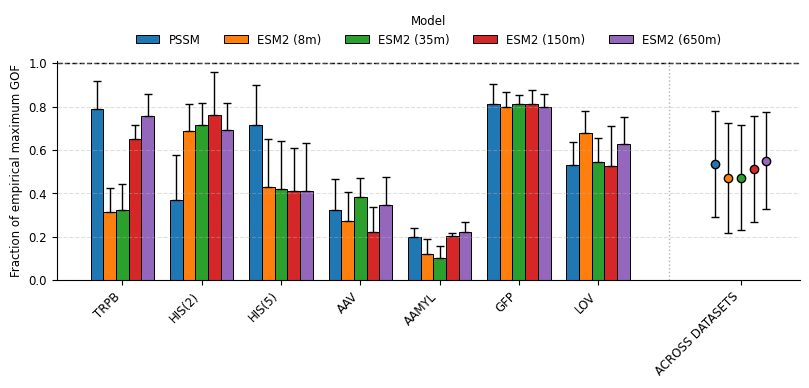

In [14]:
dataset_names = {
    "his2": "HIS(2)",
    "his5": "HIS(5)",
    "casp": "AAV",
}

base_path = "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets"
all_scores_path = f"{base_path}/library_screening_analyses/revision_all_results.pkl"
max_scores_path = f"{base_path}/library_screening_analyses/revision_greedy_max_exploration_results.pkl"
strict_all_scores_path = f"{base_path}/library_screening_analyses/strict_revision_all_results.pkl"
strict_max_scores_path = f"{base_path}/library_screening_analyses/strict_revision_greedy_max_exploration_results.pkl"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

all_results = load_pickle(all_scores_path)
max_scores = load_pickle(max_scores_path)
strict_all_results = load_pickle(strict_all_scores_path)
strict_max_scores = load_pickle(strict_max_scores_path)


fig, ax, ratio_df, _ = plot_fraction_of_empirical_max(
    all_results,
    max_scores,
    sample_settings,
    mode="unique_gof",
    dataset_order=dataset_order,
    names_dict=names_dict,
    figsize=(8.2, 4),
    text_size=8.5,
    log_y=False,
    plot_type="bar",
    bar_center="median",
    bar_error="sd",
    normalize_by_max=True,
    dataset_names=dataset_names
)

In [130]:
np.median(all_results["his2_pssm"]["unique_median_activity_matrix"] / max_scores["his2"]["unique_activity_matrix"])

0.9617967380471183

In [125]:
max_scores["his2"]

{'unique_gof_matrix': array([[ 1.96969697,  3.93939394,  9.84848485, 19.6969697 ],
        [ 1.93370166,  3.86740331,  9.66850829, 19.33701657],
        [ 1.68168168,  3.36336336,  8.40840841, 16.81681682],
        [ 1.58088235,  3.16176471,  7.90441176, 15.80882353],
        [ 1.51096282,  3.02192564,  7.55481411, 15.10962822],
        [ 1.39642239,  2.79284478,  6.98211194, 13.96422389]]),
 'unique_activity_matrix': array([[1.01893564, 1.01654526, 1.01833385, 1.01792994],
        [1.01785059, 1.01618638, 1.01586659, 1.0156986 ],
        [1.01070787, 1.00879919, 1.01038323, 1.01165649],
        [1.00819491, 1.00565355, 1.01013127, 1.00981815],
        [1.00305129, 1.00297329, 1.00396167, 1.00293925],
        [1.00092299, 1.0019422 , 1.00215894, 1.00182543]]),
 'non_unique_gof_matrix': array([[ 2.        ,  4.        , 10.        , 20.        ],
        [ 1.93370166,  3.86740331,  9.66850829, 19.33701657],
        [ 1.8134715 ,  3.62694301,  9.06735751, 18.13471503],
        [ 1.723646

In [52]:
old_max_scores['his2']["worst_sampled_muts_unique_activity"]

{3: array([ 6, 16, 32]),
 4: array([ 6, 10, 14, 32]),
 5: array([ 6, 10, 14, 26, 32]),
 6: array([ 0,  4, 10, 12, 16, 32]),
 7: array([ 3,  4, 10, 12, 14, 24, 30]),
 8: array([ 3,  4,  6,  9, 16, 24, 26, 32])}

In [89]:

print(all_results["casp_pssm"]["unique_chosen_indices"][6])
print(all_results["casp_esm2_t33_650M_UR50D"]["unique_chosen_indices"][6])
print(max_scores["casp"]["worst_sampled_muts_unique_gof"][6])
print(max_scores["casp"]["best_sampled_muts_unique_gof"][6])

[162  91  81  62  17  46]
[ 60 131 162  27  43  14]
[ 17  40  96 113 131 144]
[ 54  70  89 137 142 165]


In [31]:
all_results{"his2_pssm"}

SyntaxError: invalid syntax (3690089170.py, line 1)

In [29]:
all_results.keys()

dict_keys(['his2_pssm', 'his2_esm2_t6_8M_UR50D', 'his5_pssm', 'his5_esm2_t6_8M_UR50D', 'trpb_pssm', 'trpb_esm2_t6_8M_UR50D', 'aamyl_pssm', 'aamyl_esm2_t6_8M_UR50D', 'gfp_pssm', 'gfp_esm2_t6_8M_UR50D', 'lov_pssm', 'lov_esm2_t6_8M_UR50D', 'casp_pssm', 'casp_esm2_t6_8M_UR50D', 'pte_pssm', 'pte_esm2_t6_8M_UR50D', 'nmt_pssm', 'nmt_esm2_t6_8M_UR50D', 'gcn4_pssm', 'gcn4_esm2_t6_8M_UR50D', 'pard3_pssm', 'pard3_esm2_t6_8M_UR50D', 'his2_esm2_t12_35M_UR50D', 'his5_esm2_t12_35M_UR50D', 'trpb_esm2_t12_35M_UR50D', 'aamyl_esm2_t12_35M_UR50D', 'gfp_esm2_t12_35M_UR50D', 'lov_esm2_t12_35M_UR50D', 'casp_esm2_t12_35M_UR50D', 'pte_esm2_t12_35M_UR50D', 'nmt_esm2_t12_35M_UR50D', 'gcn4_esm2_t12_35M_UR50D', 'pard3_esm2_t12_35M_UR50D', 'his2_esm2_t30_150M_UR50D', 'his5_esm2_t30_150M_UR50D', 'trpb_esm2_t30_150M_UR50D', 'aamyl_esm2_t30_150M_UR50D', 'gfp_esm2_t30_150M_UR50D', 'lov_esm2_t30_150M_UR50D', 'casp_esm2_t30_150M_UR50D', 'pte_esm2_t30_150M_UR50D', 'nmt_esm2_t30_150M_UR50D', 'gcn4_esm2_t30_150M_UR50D', 'pa

{3: array([18,  6, 15]),
 4: array([18,  6, 15, 32]),
 5: array([18,  6, 15, 32,  9]),
 6: array([18,  6, 15, 32,  9, 26]),
 7: array([18,  6, 15, 32,  9, 26, 24]),
 8: array([18,  6, 15, 32,  9, 26, 24, 12])}

In [49]:
def plot_mutation_ranks(
    all_results,
    names_dict=None,
    model_order=None,
    dataset_order=None,
    figsize=(11, 3),
    text_size=9,
    bar_width=0.3,
    width_ratios=(5, 3, 3),
    center="median",          # "median" or "mean"
    run_stats=True,
    stat_test="kruskal",
    output_dir="refined_figures/figure_screen_analysis",
    output_name="rank.svg",
    show=True,
):
    """
    Plot mutation-ranking results directly from all_results.

    Panel 1:
        Median/mean + upper SD for best and worst mutation ranks.

    Panel 2:
        Distribution across datasets of:
            rank_delta = ranks_worst - ranks_best

        delta > 0 : worst mutations ranked worse than best mutations
        delta < 0 : worst mutations ranked BETTER than best mutations

    Panel 3:
        Median/mean + upper SD for empirical-vs-model Spearman correlation.
    """

    if center not in ["median", "mean"]:
        raise ValueError("center must be 'median' or 'mean'")

    df = build_mut_ranks_df(all_results)

    if df.empty:
        raise ValueError("No mutation-ranking results were found in all_results.")

    # =========================================================================
    # DATASET FILTERING
    # =========================================================================

    if dataset_order is not None:
        available_datasets = set(df["dataset"])
        datasets = [d for d in dataset_order if d in available_datasets]
        df = df[df["dataset"].isin(datasets)].copy()

        df["dataset"] = pd.Categorical(df["dataset"], categories=datasets, ordered=True)
        df = df.sort_values("dataset").reset_index(drop=True)

    if df.empty:
        raise ValueError("No data remain after dataset filtering.")

    # =========================================================================
    # MODEL FILTERING / ORDER
    # =========================================================================

    available_models = df["model"].drop_duplicates().tolist()

    if model_order is None:
        model_order = available_models
    else:
        model_order = [model for model in model_order if model in available_models]

    df = df[df["model"].isin(model_order)].copy()

    if df.empty:
        raise ValueError("No data remain after model filtering.")

    if names_dict is None:
        names_dict = {}

    model_labels = [names_dict.get(model, model) for model in model_order]

    # =========================================================================
    # DELTA
    # =========================================================================

    # Positive: worst mutations ranked worse than best mutations.
    # Negative: worst mutations ranked better than best mutations.
    df["rank_delta"] = df["ranks_worst"] - df["ranks_best"]

    # =========================================================================
    # STATISTICAL TESTS
    # =========================================================================

    stats_results = {}

    if run_stats:
        stats_results["ranks_best"] = print_group_test("ranks_best", df, stat_test)
        stats_results["ranks_worst"] = print_group_test("ranks_worst", df, stat_test)
        stats_results["rank_delta"] = print_group_test("rank_delta", df, stat_test)
        stats_results["spearman"] = print_group_test(
            "empirical_vs_model_prob_spearmanr", df, stat_test
        )

    # =========================================================================
    # SUMMARY ACROSS DATASETS
    # =========================================================================

    grouped = df.groupby("model", observed=True)

    if center == "mean":
        center_best = grouped["ranks_best"].mean().reindex(model_order)
        center_worst = grouped["ranks_worst"].mean().reindex(model_order)
        center_spearman = grouped["empirical_vs_model_prob_spearmanr"].mean().reindex(model_order)
    else:
        center_best = grouped["ranks_best"].median().reindex(model_order)
        center_worst = grouped["ranks_worst"].median().reindex(model_order)
        center_spearman = grouped["empirical_vs_model_prob_spearmanr"].median().reindex(model_order)

    sd_best = grouped["ranks_best"].std().reindex(model_order).fillna(0)
    sd_worst = grouped["ranks_worst"].std().reindex(model_order).fillna(0)
    sd_spearman = grouped["empirical_vs_model_prob_spearmanr"].std().reindex(model_order).fillna(0)

    # Upper-only SD
    yerr_best = np.vstack([np.zeros(len(sd_best)), sd_best.to_numpy()])
    yerr_worst = np.vstack([np.zeros(len(sd_worst)), sd_worst.to_numpy()])
    yerr_spearman = np.vstack([np.zeros(len(sd_spearman)), sd_spearman.to_numpy()])

    # =========================================================================
    # FIGURE
    # =========================================================================

    plt.rcParams["svg.fonttype"] = "none"

    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(1, 3, width_ratios=width_ratios)

    # =========================================================================
    # PANEL 1: BEST / WORST RANK
    # =========================================================================

    ax0 = fig.add_subplot(gs[0])
    x = np.arange(len(model_order))

    ax0.bar(
        x - bar_width / 2,
        center_best,
        yerr=yerr_best,
        width=bar_width,
        color="skyblue",
        edgecolor="black",
        linewidth=0.8,
        capsize=4,
        label="Best",
    )

    ax0.bar(
        x + bar_width / 2,
        center_worst,
        yerr=yerr_worst,
        width=bar_width,
        color="lightcoral",
        edgecolor="black",
        linewidth=0.8,
        capsize=4,
        label="Worst",
    )

    ax0.set_ylabel(f"Rank ({center} + SD)", fontsize=text_size)
    ax0.set_xticks(x)
    ax0.set_xticklabels(model_labels, rotation=45, ha="right", fontsize=text_size)
    ax0.tick_params(axis="y", labelsize=text_size)
    ax0.legend(fontsize=text_size, frameon=False)

    ax0.spines["top"].set_visible(False)
    ax0.spines["right"].set_visible(False)
    ax0.grid(False)

    # =========================================================================
    # PANEL 2: WORST - BEST DELTA
    # =========================================================================

    ax1 = fig.add_subplot(gs[1])

    delta_values = [
        df.loc[df["model"] == model, "rank_delta"].dropna().values
        for model in model_order
    ]

    box = ax1.boxplot(
        delta_values,
        positions=np.arange(len(model_order)),
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.2},
        whiskerprops={"color": "black", "linewidth": 0.8},
        capprops={"color": "black", "linewidth": 0.8},
        boxprops={"edgecolor": "black", "linewidth": 0.8},
    )

    for patch in box["boxes"]:
        patch.set_facecolor("lightgray")

    ax1.axhline(0, color="black", linestyle="--", linewidth=1)

    ax1.set_ylabel("Worst rank − best rank", fontsize=text_size)
    ax1.set_xticks(np.arange(len(model_order)))
    ax1.set_xticklabels(model_labels, rotation=45, ha="right", fontsize=text_size)
    ax1.tick_params(axis="y", labelsize=text_size)

    ax1.spines["top"].set_visible(False)
    ax1.spines["right"].set_visible(False)
    ax1.grid(False)

    # =========================================================================
    # PANEL 3: SPEARMAN
    # =========================================================================

    ax2 = fig.add_subplot(gs[2])
    x2 = np.arange(len(model_order))

    ax2.bar(
        x2,
        center_spearman,
        yerr=yerr_spearman,
        width=bar_width,
        color="mediumseagreen",
        edgecolor="black",
        linewidth=0.8,
        capsize=4,
    )

    ax2.set_ylabel(f"Spearman\n({center} + SD)", fontsize=text_size)
    ax2.set_xticks(x2)
    ax2.set_xticklabels(model_labels, rotation=45, ha="right", fontsize=text_size)
    ax2.tick_params(axis="y", labelsize=text_size)

    ax2.spines["top"].set_visible(False)
    ax2.spines["right"].set_visible(False)
    ax2.grid(False)

    # =========================================================================
    # SAVE
    # =========================================================================

    plt.tight_layout()

    output_path = None

    if output_dir is not None and output_name is not None:
        os.makedirs(output_dir, exist_ok=True)
        output_path = os.path.join(output_dir, output_name)
        fig.savefig(output_path, format="svg", bbox_inches="tight")
        print(f"Figure saved to {output_path}")

    if show:
        plt.show()

    return fig, (ax0, ax1, ax2), df, stats_results

=== Kruskal-Wallis: Ranks Best by Model ===
H-statistic = 0.6425, p-value = 0.9582
Models: ['esm2_t12_35M_UR50D', 'esm2_t33_650M_UR50D', 'esm2_t30_150M_UR50D', 'esm2_t6_8M_UR50D', 'pssm']

=== Kruskal-Wallis: Ranks Worst by Model ===
H-statistic = 0.6425, p-value = 0.9582
Models: ['esm2_t12_35M_UR50D', 'esm2_t33_650M_UR50D', 'esm2_t30_150M_UR50D', 'esm2_t6_8M_UR50D', 'pssm']

=== Kruskal-Wallis: Rank Delta by Model ===
H-statistic = 0.6425, p-value = 0.9582
Models: ['esm2_t12_35M_UR50D', 'esm2_t33_650M_UR50D', 'esm2_t30_150M_UR50D', 'esm2_t6_8M_UR50D', 'pssm']

=== Kruskal-Wallis: Empirical Vs Model Prob Spearmanr by Model ===
H-statistic = 0.3223, p-value = 0.9883
Models: ['esm2_t12_35M_UR50D', 'esm2_t33_650M_UR50D', 'esm2_t30_150M_UR50D', 'esm2_t6_8M_UR50D', 'pssm']

Figure saved to refined_figures/figure_screen_analysis/rank.svg


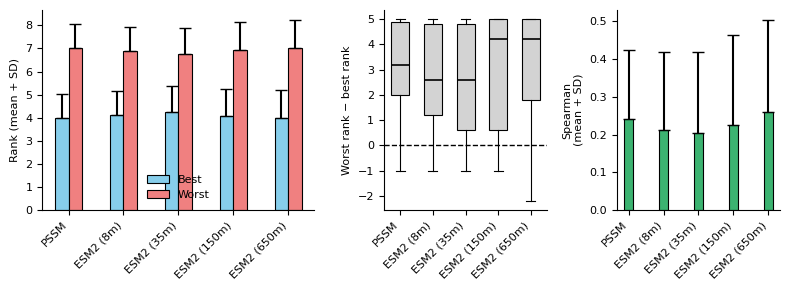

In [51]:
fig, axes, mut_ranks_df, stats_results = plot_mutation_ranks(
    all_results=all_results,
    names_dict=names_dict,
    model_order=[
        "pssm",
        "esm2_t6_8M_UR50D",
        "esm2_t12_35M_UR50D",
        "esm2_t30_150M_UR50D",
        "esm2_t33_650M_UR50D",
    ],
    dataset_order=dataset_order,
    figsize=(8, 3),
    text_size=8,
    bar_width=0.25,
    stat_test="kruskal",
    center="mean",
)

In [216]:

#old debug code
# dataset = "trpb"

# df = pd.read_csv(DATASET_PATHS[dataset])

# relevant_columns = get_relevant_columns(dataset, df)

# ohe_df = get_one_hot_encoding(df, relevant_columns)

# ohe_columns = ohe_df.columns
# ohe = ohe_df.to_numpy().astype(np.int8)

# # WT index
# wt_rows = np.where(df["num_muts"].to_numpy() == 0)[0]

# if len(wt_rows) != 1:
#     raise ValueError(f"{dataset}: expected exactly one WT row, found {len(wt_rows)}")

# wt_idx = int(wt_rows[0])

# # Actual mutation columns relative to WT
# real_mutation_cols = np.where(ohe[wt_idx, :] == 0)[0]

# # Total number of mutations in every assayed variant
# total_mutations = ohe[:, real_mutation_cols].sum(axis=1)

# # Position corresponding to every OHE column
# pos_per_ohe_column = np.asarray([
#     int(col.split("_")[0][1:])
#     for col in ohe_columns
# ])

# activity = df[datasets_and_activity[dataset]["activity_col"]].to_numpy()

# gof_threshold = np.percentile(activity, 90)

# print("OHE shape:", ohe.shape)
# print("WT index:", wt_idx)
# print("Real mutation columns:", len(real_mutation_cols))
# print("Activity shape:", activity.shape)

# s = strict_sample_settings["trpb"]["space_sizes"][0]

# pssm_muts = all_results["trpb_pssm"]["unique_chosen_indices"][s]

# candidate_indices = get_candidate_library_fast(
#     ohe=ohe,
#     chosen_mutations=pssm_muts,
#     total_mutations=total_mutations,
#     max_outside_muts=1
# )

# test_eval = evaluate_candidate_library_fast(
#     candidate_indices=candidate_indices,
#     activity=activity,
#     gof_threshold=gof_threshold,
#     k_values=strict_sample_settings["trpb"]["k_values"],
#     n_subsamples=500
# )

# print("PSSM stored:")
# print(all_results["trpb_pssm"]["unique_median_activity_matrix"][0])

# print("PSSM re-evaluated through max code:")
# print(test_eval[1])

# print("Random-search max:")
# print(max_scores["trpb"]["unique_activity_matrix"][0])

In [184]:
ohe.shape

(133605, 35)

In [99]:
print(all_results.keys())
print(max_scores.keys())

dict_keys(['his2_pssm', 'his2_esm2_t6_8M_UR50D', 'his5_pssm', 'his5_esm2_t6_8M_UR50D', 'trpb_pssm', 'trpb_esm2_t6_8M_UR50D', 'aamyl_pssm', 'aamyl_esm2_t6_8M_UR50D', 'gfp_pssm', 'gfp_esm2_t6_8M_UR50D', 'lov_pssm', 'lov_esm2_t6_8M_UR50D', 'casp_pssm', 'casp_esm2_t6_8M_UR50D', 'pte_pssm', 'pte_esm2_t6_8M_UR50D', 'nmt_pssm', 'nmt_esm2_t6_8M_UR50D', 'gcn4_pssm', 'gcn4_esm2_t6_8M_UR50D', 'pard3_pssm', 'pard3_esm2_t6_8M_UR50D', 'his2_esm2_t12_35M_UR50D', 'his5_esm2_t12_35M_UR50D', 'trpb_esm2_t12_35M_UR50D', 'aamyl_esm2_t12_35M_UR50D', 'gfp_esm2_t12_35M_UR50D', 'lov_esm2_t12_35M_UR50D', 'casp_esm2_t12_35M_UR50D', 'pte_esm2_t12_35M_UR50D', 'nmt_esm2_t12_35M_UR50D', 'gcn4_esm2_t12_35M_UR50D', 'pard3_esm2_t12_35M_UR50D', 'his2_esm2_t30_150M_UR50D', 'his5_esm2_t30_150M_UR50D', 'trpb_esm2_t30_150M_UR50D', 'aamyl_esm2_t30_150M_UR50D', 'gfp_esm2_t30_150M_UR50D', 'lov_esm2_t30_150M_UR50D', 'casp_esm2_t30_150M_UR50D', 'pte_esm2_t30_150M_UR50D', 'nmt_esm2_t30_150M_UR50D', 'gcn4_esm2_t30_150M_UR50D', 'pa

In [154]:
# import pickle
# import numpy as np
# import pandas as pd
# import seaborn as sns
# import matplotlib.pyplot as plt


# # =============================================================================
# # LOAD RESULTS
# # =============================================================================

# with open("revision_all_results.pkl", "rb") as f:
#     all_results = pickle.load(f)


# # =============================================================================
# # BUILD DATAFRAME FROM SAVED unique_metadata
# # =============================================================================

# rows = []

# for key, res in all_results.items():

#     if res.get("unique_metadata") is None:
#         continue

#     # Find dataset from beginning of key, e.g. "his2_pssm"
#     dataset = next((ds for ds in dataset_order if key.startswith(ds + "_")), None)

#     if dataset is None:
#         print(f"Could not determine dataset for key: {key}")
#         continue

#     model = key[len(dataset) + 1:]

#     for s, meta in res["unique_metadata"].items():

#         overlap = np.asarray(meta["chosen_overlap"], dtype=float)
#         outside = np.asarray(meta["muts_outside"], dtype=float)

#         # For UNIQUE libraries:
#         # overlap = n_inside / S
#         inside = overlap * s

#         total_muts = inside + outside

#         frac_outside = np.divide(
#             outside,
#             total_muts,
#             out=np.zeros_like(outside, dtype=float),
#             where=total_muts > 0
#         )

#         # Reviewer-relevant quantity:
#         # total mutational order of assayed sequence relative to nominated S
#         relative_mut_order = total_muts / s

#         for ov, inn, out, total, frac_out, rel_order in zip(
#             overlap,
#             inside,
#             outside,
#             total_muts,
#             frac_outside,
#             relative_mut_order
#         ):
#             rows.append({
#                 "dataset": dataset,
#                 "model": model,
#                 "s": int(s),

#                 # Fraction of nominated mutations represented
#                 "overlap": ov,

#                 # Raw counts, useful for later checks
#                 "muts_inside": inn,
#                 "muts_outside": out,
#                 "num_muts": total,

#                 # Fraction of mutations in the empirical variant
#                 # that do NOT belong to the nominated library
#                 "frac_outside": frac_out,

#                 # (n_inside + n_outside) / S
#                 "relative_mut_order": rel_order
#             })


# plot_df = pd.DataFrame(rows)

# print(plot_df.shape)
# display(plot_df.head())


# # =============================================================================
# # OPTIONAL ORDERS
# # =============================================================================

# plot_dataset_order = [
#     ds for ds in dataset_order
#     if ds in plot_df["dataset"].unique()
# ]

# # Preserve whatever ordering you want here.
# # Otherwise this automatically uses the order encountered in all_results.
# model_order = list(plot_df["model"].drop_duplicates())

# s_values = sorted(plot_df["s"].unique())


# # =============================================================================
# # PLOT: ONE ROW PER S, THREE REVIEWER-RELEVANT METRICS
# # =============================================================================

# metrics = [
#     ("overlap", "Fraction of nominated mutations present"),
#     ("frac_outside", "Fraction of mutations outside library"),
#     ("relative_mut_order", r"Relative mutational order $(n_{in}+n_{out})/S$")
# ]

# fig, axes = plt.subplots(
#     nrows=len(s_values),
#     ncols=3,
#     figsize=(18, 3.2 * len(s_values)),
#     sharex="col",
#     sharey="col",
#     squeeze=False
# )


# for i, s in enumerate(s_values):

#     sdf = plot_df[plot_df["s"] == s]

#     for j, (metric, title) in enumerate(metrics):

#         ax = axes[i, j]

#         sns.boxplot(
#             data=sdf,
#             x="dataset",
#             y=metric,
#             hue="model",
#             order=plot_dataset_order,
#             hue_order=model_order,
#             showfliers=False,
#             ax=ax
#         )

#         # -------------------------------------------------------------
#         # Titles only on top row
#         # -------------------------------------------------------------
#         if i == 0:
#             ax.set_title(title)

#         # -------------------------------------------------------------
#         # S label on left-hand side
#         # -------------------------------------------------------------
#         if j == 0:
#             ax.set_ylabel(f"S = {s}")
#         else:
#             ax.set_ylabel("")

#         ax.set_xlabel("")

#         # -------------------------------------------------------------
#         # Reviewer reference line:
#         # relative mutational order = 1 means exact agreement with S
#         # -------------------------------------------------------------
#         if metric == "relative_mut_order":
#             ax.axhline(1, ls="--", color="black", lw=1)

#         # Useful fixed limits for the two fractional quantities
#         if metric == "overlap":
#             ax.set_ylim(0, 1.05)

#         elif metric == "frac_outside":
#             ax.set_ylim(0, 0.55)

#         # -------------------------------------------------------------
#         # Only show dataset labels on bottom row
#         # -------------------------------------------------------------
#         if i == len(s_values) - 1:
#             ax.tick_params(axis="x", rotation=45)
#         else:
#             ax.tick_params(axis="x", labelbottom=False)

#         # Remove individual legends
#         if ax.legend_ is not None:
#             ax.legend_.remove()


# # =============================================================================
# # COMMON LEGEND
# # =============================================================================

# handles, labels = axes[0, 0].get_legend_handles_labels()

# fig.legend(
#     handles,
#     labels,
#     title="Model",
#     bbox_to_anchor=(1.005, 0.5),
#     loc="center left",
#     frameon=True
# )


# plt.tight_layout(rect=[0, 0, 0.88, 1])
# plt.show()

In [217]:
# import os
# import pickle
# import numpy as np
# import pandas as pd


# # =============================================================================
# # SETTINGS
# # =============================================================================

# overwrite = True

# N_LIBRARY_SEARCH_ITERS = 10000

# # Cheap estimate used while searching through 10,000 nominated libraries.
# # This is ONLY needed for median activity. GOF is computed exactly.
# SEARCH_N_SUBSAMPLES = 5

# # Once the winning mutation sets have been found, estimate their median-activity
# # performance much more accurately.
# FINAL_N_SUBSAMPLES = 500

# # Main analysis:
# MAX_OUTSIDE_MUTS = 1

# # Strict sensitivity analysis:
# # MAX_OUTSIDE_MUTS = 0

# if strict:
#     max_scores_path = "strict_revision_max_exploration_results.pkl"
# else:
#     max_scores_path = "revision_max_exploration_results.pkl"

# print("Saving to: %s" % max_scores_path)

# # =============================================================================
# # HELPERS
# # =============================================================================

# def sample_empirical_mutations(real_mutation_cols, pos_per_ohe_column, s, unique_mutations=True):
#     """
#     Randomly nominate S actual mutation columns.

#     unique_mutations=True:
#         At most one nominated substitution per sequence position.

#     unique_mutations=False:
#         Multiple alternative substitutions at the same position are allowed.
#     """

#     if not unique_mutations:
#         if len(real_mutation_cols) < s:
#             return None

#         return np.random.choice(real_mutation_cols, size=s, replace=False)

#     shuffled_cols = np.random.permutation(real_mutation_cols)

#     chosen = []
#     seen_positions = set()

#     for col_idx in shuffled_cols:
#         pos = pos_per_ohe_column[col_idx]

#         if pos not in seen_positions:
#             seen_positions.add(pos)
#             chosen.append(col_idx)

#         if len(chosen) == s:
#             break

#     if len(chosen) < s:
#         return None

#     return np.asarray(chosen, dtype=int)


# def get_candidate_library_fast(ohe, chosen_mutations, total_mutations, max_outside_muts=1):
#     """
#     Define the empirical nominated sub-library.

#     A sequence is included when:
#         1. It contains at least one nominated substitution.
#         2. It contains <= max_outside_muts substitutions outside the nomination.

#     Because chosen_mutations contains only actual mutations:

#         outside = total_mutations - inside
#     """

#     inside = ohe[:, chosen_mutations].sum(axis=1)
#     outside = total_mutations - inside

#     candidate_mask = (inside > 0) & (outside <= max_outside_muts)

#     return np.flatnonzero(candidate_mask)


# def evaluate_candidate_library_fast(candidate_indices, activity, gof_threshold, k_values, n_subsamples=5):
#     """
#     Evaluate one nominated empirical sub-library.

#     GOF:
#         Computed exactly as the expected number of GOF variants in a random
#         K-sized sample:

#             E[#GOF] = K * (#GOF / N)

#         No Monte Carlo is required.

#     Median activity:
#         Estimated by repeated random permutations. One permutation supplies
#         all K values by taking prefixes.
#     """

#     n_candidates = len(candidate_indices)
#     max_k = max(k_values)

#     if n_candidates < max_k:
#         return None

#     candidate_activity = activity[candidate_indices]

#     # -------------------------------------------------------------------------
#     # EXACT EXPECTED GOF
#     # -------------------------------------------------------------------------

#     gof_fraction = np.mean(candidate_activity > gof_threshold)

#     gof_vec = np.asarray(k_values, dtype=float) * gof_fraction

#     # -------------------------------------------------------------------------
#     # MONTE CARLO MEDIAN ACTIVITY
#     # -------------------------------------------------------------------------

#     activity_samples = np.zeros((n_subsamples, len(k_values)), dtype=float)

#     for i in range(n_subsamples):
#         shuffled_activity = candidate_activity[np.random.permutation(n_candidates)]

#         for k_idx, k in enumerate(k_values):
#             activity_samples[i, k_idx] = np.median(shuffled_activity[:k])

#     activity_vec = np.median(activity_samples, axis=0)

#     return gof_vec, activity_vec


# def reevaluate_library(
#     ohe,
#     chosen_mutations,
#     total_mutations,
#     activity,
#     gof_threshold,
#     k_values,
#     max_outside_muts,
#     n_subsamples
# ):
#     """
#     High-precision reevaluation of one already-selected winning/losing library.
#     """

#     if chosen_mutations is None:
#         return None

#     candidate_indices = get_candidate_library_fast(
#         ohe=ohe,
#         chosen_mutations=chosen_mutations,
#         total_mutations=total_mutations,
#         max_outside_muts=max_outside_muts
#     )

#     result = evaluate_candidate_library_fast(
#         candidate_indices=candidate_indices,
#         activity=activity,
#         gof_threshold=gof_threshold,
#         k_values=k_values,
#         n_subsamples=n_subsamples
#     )

#     if result is None:
#         return None

#     gof_vec, activity_vec = result

#     return {
#         "gof": gof_vec,
#         "activity": activity_vec,
#         "n_candidates": len(candidate_indices)
#     }


# # =============================================================================
# # LOAD PREVIOUS RESULTS
# # =============================================================================

# if not overwrite and os.path.exists(max_scores_path):
#     with open(max_scores_path, "rb") as f:
#         max_scores = pickle.load(f)
# else:
#     max_scores = {}


# # =============================================================================
# # DATASET LOOP
# # =============================================================================

# if strict:
#     work_sample = strict_sample_settings
# else:
#     work_sample = sample_settings

    
# for dataset in dataset_order:

#     if dataset in datasets_to_skip_lib_gen:
#         continue

#     if dataset in max_scores:
#         print(f"Skipping {dataset} because it already exists")
#         continue

#     print(f"\n======= Processing {dataset} =======")

#     space_sizes = work_sample[dataset]["space_sizes"]
#     k_values = work_sample[dataset]["k_values"]

#     df = pd.read_csv(DATASET_PATHS[dataset])

#     relevant_columns = get_relevant_columns(dataset, df)

#     ohe_df = get_one_hot_encoding(df, relevant_columns)
#     ohe_columns = ohe_df.columns
#     ohe = ohe_df.to_numpy().astype(np.int8)

#     pos_per_ohe_column = np.asarray([int(col.split("_")[0][1:]) for col in ohe_columns])

#     activity = df[datasets_and_activity[dataset]["activity_col"]].to_numpy()

#     if dataset == "gfp":
#         activity = (~activity).astype(int)


#     # =========================================================================
#     # WT
#     # =========================================================================

#     wt_rows = np.where(df["num_muts"].to_numpy() == 0)[0]

#     if len(wt_rows) != 1:
#         raise ValueError(f"{dataset}: expected exactly one WT row, found {len(wt_rows)}")

#     wt_idx = int(wt_rows[0])


#     # =========================================================================
#     # PRECOMPUTE EVERYTHING THAT DOES NOT CHANGE BETWEEN LIBRARIES
#     # =========================================================================

#     # Every OHE column for which WT has 0 corresponds to an actual mutation.
#     real_mutation_cols = np.where(ohe[wt_idx, :] == 0)[0]

#     # Number of actual mutations in every measured variant.
#     #
#     # This expensive operation is done ONCE per dataset.
#     #
#     # For every nominated library afterward:
#     #
#     #     outside = total_mutations - inside
#     #
#     total_mutations = ohe[:, real_mutation_cols].sum(axis=1)

#     gof_threshold = np.percentile(activity, 90)

#     print(f"Variants: {len(df)}")
#     print(f"Mutation columns: {len(real_mutation_cols)}")
#     print(f"Maximum K: {max(k_values)}")


#     # =========================================================================
#     # RESULT MATRICES
#     # =========================================================================

#     shape = (len(space_sizes), len(k_values))

#     unique_max_matrix_gof = np.full(shape, -np.inf)
#     unique_max_matrix_activity = np.full(shape, -np.inf)

#     non_unique_max_matrix_gof = np.full(shape, -np.inf)
#     non_unique_max_matrix_activity = np.full(shape, -np.inf)

#     unique_min_matrix_gof = np.full(shape, np.inf)
#     unique_min_matrix_activity = np.full(shape, np.inf)

#     non_unique_min_matrix_gof = np.full(shape, np.inf)
#     non_unique_min_matrix_activity = np.full(shape, np.inf)


#     # =========================================================================
#     # STORE MUTATION SETS THAT GENERATED THE EXTREMES
#     # =========================================================================

#     best_sampled_muts_unique_gof = {}
#     best_sampled_muts_unique_activity = {}

#     best_sampled_muts_non_unique_gof = {}
#     best_sampled_muts_non_unique_activity = {}

#     worst_sampled_muts_unique_gof = {}
#     worst_sampled_muts_unique_activity = {}

#     worst_sampled_muts_non_unique_gof = {}
#     worst_sampled_muts_non_unique_activity = {}


#     # Number of candidates in the winning libraries.
#     best_library_size_unique_gof = {}
#     best_library_size_unique_activity = {}

#     best_library_size_non_unique_gof = {}
#     best_library_size_non_unique_activity = {}


#     # =========================================================================
#     # SEARCH OVER S
#     # =========================================================================

#     for s_idx, s in enumerate(space_sizes):

#         print(f"\ns: {s}")

#         n_valid_unique = 0
#         n_valid_non_unique = 0


#         for iteration in range(N_LIBRARY_SEARCH_ITERS):

#             # =================================================================
#             # UNIQUE-POSITION LIBRARY
#             # =================================================================

#             unique_sampled_col_indices = sample_empirical_mutations(
#                 real_mutation_cols=real_mutation_cols,
#                 pos_per_ohe_column=pos_per_ohe_column,
#                 s=s,
#                 unique_mutations=True
#             )

#             if unique_sampled_col_indices is not None:

#                 unique_candidate_indices = get_candidate_library_fast(
#                     ohe=ohe,
#                     chosen_mutations=unique_sampled_col_indices,
#                     total_mutations=total_mutations,
#                     max_outside_muts=MAX_OUTSIDE_MUTS
#                 )

#                 unique_eval = evaluate_candidate_library_fast(
#                     candidate_indices=unique_candidate_indices,
#                     activity=activity,
#                     gof_threshold=gof_threshold,
#                     k_values=k_values,
#                     n_subsamples=SEARCH_N_SUBSAMPLES
#                 )

#                 if unique_eval is not None:

#                     n_valid_unique += 1

#                     unique_complete_k_vec_gof, unique_complete_k_vec_activity = unique_eval


#                     # ---------------------------------------------------------
#                     # BEST UNIQUE GOF
#                     # ---------------------------------------------------------

#                     if unique_complete_k_vec_gof.sum() > unique_max_matrix_gof[s_idx].sum():

#                         unique_max_matrix_gof[s_idx] = unique_complete_k_vec_gof

#                         best_sampled_muts_unique_gof[s] = unique_sampled_col_indices.copy()

#                         best_library_size_unique_gof[s] = len(unique_candidate_indices)


#                     # ---------------------------------------------------------
#                     # BEST UNIQUE ACTIVITY
#                     # ---------------------------------------------------------

#                     if unique_complete_k_vec_activity.sum() > unique_max_matrix_activity[s_idx].sum():

#                         unique_max_matrix_activity[s_idx] = unique_complete_k_vec_activity

#                         best_sampled_muts_unique_activity[s] = unique_sampled_col_indices.copy()

#                         best_library_size_unique_activity[s] = len(unique_candidate_indices)


#                     # ---------------------------------------------------------
#                     # WORST UNIQUE GOF
#                     # ---------------------------------------------------------

#                     if unique_complete_k_vec_gof.sum() < unique_min_matrix_gof[s_idx].sum():

#                         unique_min_matrix_gof[s_idx] = unique_complete_k_vec_gof

#                         worst_sampled_muts_unique_gof[s] = unique_sampled_col_indices.copy()


#                     # ---------------------------------------------------------
#                     # WORST UNIQUE ACTIVITY
#                     # ---------------------------------------------------------

#                     if unique_complete_k_vec_activity.sum() < unique_min_matrix_activity[s_idx].sum():

#                         unique_min_matrix_activity[s_idx] = unique_complete_k_vec_activity

#                         worst_sampled_muts_unique_activity[s] = unique_sampled_col_indices.copy()


#             # =================================================================
#             # NON-UNIQUE LIBRARY
#             # =================================================================

#             non_unique_sampled_col_indices = sample_empirical_mutations(
#                 real_mutation_cols=real_mutation_cols,
#                 pos_per_ohe_column=pos_per_ohe_column,
#                 s=s,
#                 unique_mutations=False
#             )

#             if non_unique_sampled_col_indices is not None:

#                 non_unique_candidate_indices = get_candidate_library_fast(
#                     ohe=ohe,
#                     chosen_mutations=non_unique_sampled_col_indices,
#                     total_mutations=total_mutations,
#                     max_outside_muts=MAX_OUTSIDE_MUTS
#                 )

#                 non_unique_eval = evaluate_candidate_library_fast(
#                     candidate_indices=non_unique_candidate_indices,
#                     activity=activity,
#                     gof_threshold=gof_threshold,
#                     k_values=k_values,
#                     n_subsamples=SEARCH_N_SUBSAMPLES
#                 )

#                 if non_unique_eval is not None:

#                     n_valid_non_unique += 1

#                     non_unique_complete_k_vec_gof, non_unique_complete_k_vec_activity = non_unique_eval


#                     # ---------------------------------------------------------
#                     # BEST NON-UNIQUE GOF
#                     # ---------------------------------------------------------

#                     if non_unique_complete_k_vec_gof.sum() > non_unique_max_matrix_gof[s_idx].sum():

#                         non_unique_max_matrix_gof[s_idx] = non_unique_complete_k_vec_gof

#                         best_sampled_muts_non_unique_gof[s] = non_unique_sampled_col_indices.copy()

#                         best_library_size_non_unique_gof[s] = len(non_unique_candidate_indices)


#                     # ---------------------------------------------------------
#                     # BEST NON-UNIQUE ACTIVITY
#                     # ---------------------------------------------------------

#                     if non_unique_complete_k_vec_activity.sum() > non_unique_max_matrix_activity[s_idx].sum():

#                         non_unique_max_matrix_activity[s_idx] = non_unique_complete_k_vec_activity

#                         best_sampled_muts_non_unique_activity[s] = non_unique_sampled_col_indices.copy()

#                         best_library_size_non_unique_activity[s] = len(non_unique_candidate_indices)


#                     # ---------------------------------------------------------
#                     # WORST NON-UNIQUE GOF
#                     # ---------------------------------------------------------

#                     if non_unique_complete_k_vec_gof.sum() < non_unique_min_matrix_gof[s_idx].sum():

#                         non_unique_min_matrix_gof[s_idx] = non_unique_complete_k_vec_gof

#                         worst_sampled_muts_non_unique_gof[s] = non_unique_sampled_col_indices.copy()


#                     # ---------------------------------------------------------
#                     # WORST NON-UNIQUE ACTIVITY
#                     # ---------------------------------------------------------

#                     if non_unique_complete_k_vec_activity.sum() < non_unique_min_matrix_activity[s_idx].sum():

#                         non_unique_min_matrix_activity[s_idx] = non_unique_complete_k_vec_activity

#                         worst_sampled_muts_non_unique_activity[s] = non_unique_sampled_col_indices.copy()


#         print(
#             f"Valid libraries: "
#             f"unique={n_valid_unique}/{N_LIBRARY_SEARCH_ITERS}, "
#             f"non-unique={n_valid_non_unique}/{N_LIBRARY_SEARCH_ITERS}"
#         )


#     # =========================================================================
#     # HIGH-PRECISION REEVALUATION OF WINNING / LOSING LIBRARIES
#     # =========================================================================

#     print("\nRe-evaluating selected libraries with "
#           f"{FINAL_N_SUBSAMPLES} activity subsamples...")


#     for s_idx, s in enumerate(space_sizes):

#         # ---------------------------------------------------------------------
#         # UNIQUE: BEST GOF
#         # ---------------------------------------------------------------------

#         if s in best_sampled_muts_unique_gof:

#             final_eval = reevaluate_library(
#                 ohe=ohe,
#                 chosen_mutations=best_sampled_muts_unique_gof[s],
#                 total_mutations=total_mutations,
#                 activity=activity,
#                 gof_threshold=gof_threshold,
#                 k_values=k_values,
#                 max_outside_muts=MAX_OUTSIDE_MUTS,
#                 n_subsamples=FINAL_N_SUBSAMPLES
#             )

#             if final_eval is not None:
#                 unique_max_matrix_gof[s_idx] = final_eval["gof"]
#                 best_library_size_unique_gof[s] = final_eval["n_candidates"]


#         # ---------------------------------------------------------------------
#         # UNIQUE: BEST ACTIVITY
#         # ---------------------------------------------------------------------

#         if s in best_sampled_muts_unique_activity:

#             final_eval = reevaluate_library(
#                 ohe=ohe,
#                 chosen_mutations=best_sampled_muts_unique_activity[s],
#                 total_mutations=total_mutations,
#                 activity=activity,
#                 gof_threshold=gof_threshold,
#                 k_values=k_values,
#                 max_outside_muts=MAX_OUTSIDE_MUTS,
#                 n_subsamples=FINAL_N_SUBSAMPLES
#             )

#             if final_eval is not None:
#                 unique_max_matrix_activity[s_idx] = final_eval["activity"]
#                 best_library_size_unique_activity[s] = final_eval["n_candidates"]


#         # ---------------------------------------------------------------------
#         # UNIQUE: WORST GOF
#         # ---------------------------------------------------------------------

#         if s in worst_sampled_muts_unique_gof:

#             final_eval = reevaluate_library(
#                 ohe=ohe,
#                 chosen_mutations=worst_sampled_muts_unique_gof[s],
#                 total_mutations=total_mutations,
#                 activity=activity,
#                 gof_threshold=gof_threshold,
#                 k_values=k_values,
#                 max_outside_muts=MAX_OUTSIDE_MUTS,
#                 n_subsamples=FINAL_N_SUBSAMPLES
#             )

#             if final_eval is not None:
#                 unique_min_matrix_gof[s_idx] = final_eval["gof"]


#         # ---------------------------------------------------------------------
#         # UNIQUE: WORST ACTIVITY
#         # ---------------------------------------------------------------------

#         if s in worst_sampled_muts_unique_activity:

#             final_eval = reevaluate_library(
#                 ohe=ohe,
#                 chosen_mutations=worst_sampled_muts_unique_activity[s],
#                 total_mutations=total_mutations,
#                 activity=activity,
#                 gof_threshold=gof_threshold,
#                 k_values=k_values,
#                 max_outside_muts=MAX_OUTSIDE_MUTS,
#                 n_subsamples=FINAL_N_SUBSAMPLES
#             )

#             if final_eval is not None:
#                 unique_min_matrix_activity[s_idx] = final_eval["activity"]


#         # ---------------------------------------------------------------------
#         # NON-UNIQUE: BEST GOF
#         # ---------------------------------------------------------------------

#         if s in best_sampled_muts_non_unique_gof:

#             final_eval = reevaluate_library(
#                 ohe=ohe,
#                 chosen_mutations=best_sampled_muts_non_unique_gof[s],
#                 total_mutations=total_mutations,
#                 activity=activity,
#                 gof_threshold=gof_threshold,
#                 k_values=k_values,
#                 max_outside_muts=MAX_OUTSIDE_MUTS,
#                 n_subsamples=FINAL_N_SUBSAMPLES
#             )

#             if final_eval is not None:
#                 non_unique_max_matrix_gof[s_idx] = final_eval["gof"]
#                 best_library_size_non_unique_gof[s] = final_eval["n_candidates"]


#         # ---------------------------------------------------------------------
#         # NON-UNIQUE: BEST ACTIVITY
#         # ---------------------------------------------------------------------

#         if s in best_sampled_muts_non_unique_activity:

#             final_eval = reevaluate_library(
#                 ohe=ohe,
#                 chosen_mutations=best_sampled_muts_non_unique_activity[s],
#                 total_mutations=total_mutations,
#                 activity=activity,
#                 gof_threshold=gof_threshold,
#                 k_values=k_values,
#                 max_outside_muts=MAX_OUTSIDE_MUTS,
#                 n_subsamples=FINAL_N_SUBSAMPLES
#             )

#             if final_eval is not None:
#                 non_unique_max_matrix_activity[s_idx] = final_eval["activity"]
#                 best_library_size_non_unique_activity[s] = final_eval["n_candidates"]


#         # ---------------------------------------------------------------------
#         # NON-UNIQUE: WORST GOF
#         # ---------------------------------------------------------------------

#         if s in worst_sampled_muts_non_unique_gof:

#             final_eval = reevaluate_library(
#                 ohe=ohe,
#                 chosen_mutations=worst_sampled_muts_non_unique_gof[s],
#                 total_mutations=total_mutations,
#                 activity=activity,
#                 gof_threshold=gof_threshold,
#                 k_values=k_values,
#                 max_outside_muts=MAX_OUTSIDE_MUTS,
#                 n_subsamples=FINAL_N_SUBSAMPLES
#             )

#             if final_eval is not None:
#                 non_unique_min_matrix_gof[s_idx] = final_eval["gof"]


#         # ---------------------------------------------------------------------
#         # NON-UNIQUE: WORST ACTIVITY
#         # ---------------------------------------------------------------------

#         if s in worst_sampled_muts_non_unique_activity:

#             final_eval = reevaluate_library(
#                 ohe=ohe,
#                 chosen_mutations=worst_sampled_muts_non_unique_activity[s],
#                 total_mutations=total_mutations,
#                 activity=activity,
#                 gof_threshold=gof_threshold,
#                 k_values=k_values,
#                 max_outside_muts=MAX_OUTSIDE_MUTS,
#                 n_subsamples=FINAL_N_SUBSAMPLES
#             )

#             if final_eval is not None:
#                 non_unique_min_matrix_activity[s_idx] = final_eval["activity"]


#     # =========================================================================
#     # SAVE RESULTS
#     # =========================================================================

#     results = {
#         "unique_gof_matrix": unique_max_matrix_gof,
#         "unique_activity_matrix": unique_max_matrix_activity,

#         "non_unique_gof_matrix": non_unique_max_matrix_gof,
#         "non_unique_activity_matrix": non_unique_max_matrix_activity,

#         "min_unique_gof_matrix": unique_min_matrix_gof,
#         "min_unique_activity_matrix": unique_min_matrix_activity,

#         "min_non_unique_gof_matrix": non_unique_min_matrix_gof,
#         "min_non_unique_activity_matrix": non_unique_min_matrix_activity,

#         "best_sampled_muts_unique_gof": best_sampled_muts_unique_gof,
#         "best_sampled_muts_unique_activity": best_sampled_muts_unique_activity,

#         "best_sampled_muts_non_unique_gof": best_sampled_muts_non_unique_gof,
#         "best_sampled_muts_non_unique_activity": best_sampled_muts_non_unique_activity,

#         "worst_sampled_muts_unique_gof": worst_sampled_muts_unique_gof,
#         "worst_sampled_muts_unique_activity": worst_sampled_muts_unique_activity,

#         "worst_sampled_muts_non_unique_gof": worst_sampled_muts_non_unique_gof,
#         "worst_sampled_muts_non_unique_activity": worst_sampled_muts_non_unique_activity,

#         "best_library_size_unique_gof": best_library_size_unique_gof,
#         "best_library_size_unique_activity": best_library_size_unique_activity,

#         "best_library_size_non_unique_gof": best_library_size_non_unique_gof,
#         "best_library_size_non_unique_activity": best_library_size_non_unique_activity,

#         "max_outside_muts": MAX_OUTSIDE_MUTS,
#         "n_library_search_iters": N_LIBRARY_SEARCH_ITERS,
#         "search_n_subsamples": SEARCH_N_SUBSAMPLES,
#         "final_n_subsamples": FINAL_N_SUBSAMPLES
#     }

#     max_scores[dataset] = results

#     with open(max_scores_path, "wb") as f:
#         pickle.dump(max_scores, f)

#     print(f"Finished {dataset} and saved checkpoint.")

In [ ]:
# overwrite = True
# # Try to read max_scores from 'max_exploration_results.pkl' if it exists, unless overwrite is set
# max_scores_path = 'revision_max_exploration_results.pkl'
# if not overwrite and os.path.exists(max_scores_path):
#     with open(max_scores_path, 'rb') as f:
#         max_scores = pickle.load(f)
# else:
#     max_scores = {}

#     for dataset in dataset_order:



#         if dataset in max_scores:
#             print("Skipping %s because it already exists" % dataset)
#             continue


#         print("======= Processing %s =======" % dataset)
#         space_sizes = sample_settings[dataset]["space_sizes"]
#         k_values = sample_settings[dataset]["k_values"]
#         df = pd.read_csv(DATASET_PATHS[dataset])

#         relevant_columns = get_relevant_columns(dataset, df)
#         ohe = get_one_hot_encoding(df, relevant_columns)
#         ohe_columns = ohe.columns
#         ohe = ohe.to_numpy().astype(int)
#         pos_per_ohe_column =  [int(a.split("_")[0][1:]) for a in ohe_columns]

#         activity = df[datasets_and_activity[dataset]["activity_col"]].to_numpy()
#         if dataset == "gfp":
#             activity = (~activity).astype(int)

#         gof_threshold = np.percentile(activity, 90)

#         non_unique_max_matrix_gof = np.zeros((len(space_sizes), len(k_values)))
#         non_unique_max_matrix_activity = np.zeros((len(space_sizes), len(k_values)))

#         non_unique_min_matrix_gof = np.zeros((len(space_sizes), len(k_values)))
#         non_unique_min_matrix_activity = np.zeros((len(space_sizes), len(k_values)))

#         # Initialize the min matrices with large values for comparison
#         non_unique_min_matrix_gof[:,:] = np.inf
#         non_unique_min_matrix_activity[:,:] = np.inf

#         unique_max_matrix_gof = np.zeros((len(space_sizes), len(k_values)))
#         unique_max_matrix_activity = np.zeros((len(space_sizes), len(k_values)))

#         unique_min_matrix_gof = np.zeros((len(space_sizes), len(k_values)))
#         unique_min_matrix_activity = np.zeros((len(space_sizes), len(k_values)))

#         # Initialize the min matrices with large values for comparison
#         unique_min_matrix_gof[:,:] = np.inf
#         unique_min_matrix_activity[:,:] = np.inf

#         best_sampled_muts_unique_gof = {}
#         best_sampled_muts_non_unique_gof = {}
#         worst_sampled_muts_unique_gof = {}
#         worst_sampled_muts_non_unique_gof = {}

#         best_sampled_muts_unique_activity = {}
#         best_sampled_muts_non_unique_activity = {}
#         worst_sampled_muts_unique_activity = {}
#         worst_sampled_muts_non_unique_activity = {}

#         for s_idx, s in enumerate(space_sizes):
#             print("s: %d" % s)

#             for iter in range(10000):
#                 non_unique_sampled_col_indices = np.random.choice(ohe.shape[1], s, replace=False)
#                 non_unique_closest_to_subspace = np.argsort(
#                     -ohe[:, non_unique_sampled_col_indices].sum(axis=1)
#                 )

#                 seen = set()
#                 unique_sampled_col_indices = []
#                 indices = list(range(len(pos_per_ohe_column)))

#                 random.shuffle(indices)
#                 for idx in indices:
#                     val = pos_per_ohe_column[idx]
#                     if val not in seen:
#                         seen.add(val)
#                         unique_sampled_col_indices.append(idx)
#                     if len(unique_sampled_col_indices) == s:
#                         break
                    
#                 unique_sampled_col_indices  # List of s indexes with unique values in pos_per_ohe_column
#                 unique_closest_to_subspace = np.argsort(
#                     -ohe[:, unique_sampled_col_indices].sum(axis=1)
#                 )

#                 unique_complete_k_vec_gof = np.zeros(len(k_values))
#                 unique_complete_k_vec_activity = np.zeros(len(k_values))
#                 non_unique_complete_k_vec_gof = np.zeros(len(k_values))
#                 non_unique_complete_k_vec_activity = np.zeros(len(k_values))

#                 # For each top-K
#                 for k_idx, k in enumerate(k_values):
#                     # Unique mutations computation (as in original):
#                     activties_unique = activity[unique_closest_to_subspace[:k]]
#                     num_of_gof_unique = np.sum(activties_unique > gof_threshold)
#                     median_activity_unique = np.median(activties_unique)
#                     unique_complete_k_vec_gof[k_idx] = num_of_gof_unique
#                     unique_complete_k_vec_activity[k_idx] = median_activity_unique

#                     ####### non_unique mutations computation (as in original):
#                     # Number of GOF (above upper 90th percentile)
#                     activties_non_unique = activity[non_unique_closest_to_subspace[:k]]
#                     num_of_gof_non_unique = np.sum(activties_non_unique > gof_threshold)            
#                     median_activity_non_unique = np.median(activties_non_unique)
#                     non_unique_complete_k_vec_gof[k_idx] = num_of_gof_non_unique
#                     non_unique_complete_k_vec_activity[k_idx] = median_activity_non_unique                

#                 # Update maximum for unique
#                 if unique_complete_k_vec_gof.sum() > unique_max_matrix_gof[s_idx].sum():
#                     unique_max_matrix_gof[s_idx] = unique_complete_k_vec_gof
#                     best_sampled_muts_unique_gof[s] = unique_sampled_col_indices


#                 if unique_complete_k_vec_activity.sum() > unique_max_matrix_activity[s_idx].sum():
#                     unique_max_matrix_activity[s_idx] = unique_complete_k_vec_activity
#                     best_sampled_muts_unique_activity[s] = unique_sampled_col_indices

#                 # Update minimum for unique
#                 if (unique_complete_k_vec_gof.sum() < unique_min_matrix_gof[s_idx].sum()) and (unique_complete_k_vec_gof.sum() > 1):
#                     unique_min_matrix_gof[s_idx] = unique_complete_k_vec_gof
#                     worst_sampled_muts_unique_gof[s] = unique_sampled_col_indices

#                 if (unique_complete_k_vec_activity.sum() < unique_min_matrix_activity[s_idx].sum()) and (unique_complete_k_vec_gof.sum() > 1):
#                     unique_min_matrix_activity[s_idx] = unique_complete_k_vec_activity
#                     worst_sampled_muts_unique_activity[s] = unique_sampled_col_indices


#                 # Update maximum for unique
#                 if non_unique_complete_k_vec_gof.sum() > non_unique_max_matrix_gof[s_idx].sum():
#                     non_unique_max_matrix_gof[s_idx] = non_unique_complete_k_vec_gof
#                     best_sampled_muts_non_unique_gof[s] = non_unique_sampled_col_indices
                    
#                 if non_unique_complete_k_vec_activity.sum() > non_unique_max_matrix_activity[s_idx].sum():
#                     non_unique_max_matrix_activity[s_idx] = non_unique_complete_k_vec_activity
#                     best_sampled_muts_non_unique_activity[s] = non_unique_sampled_col_indices

#                 # Update minimum for unique
#                 if (non_unique_complete_k_vec_gof.sum() < non_unique_min_matrix_gof[s_idx].sum()) and (non_unique_complete_k_vec_gof.sum() > 1):
#                     non_unique_min_matrix_gof[s_idx] = non_unique_complete_k_vec_gof
#                     worst_sampled_muts_non_unique_gof[s] = non_unique_sampled_col_indices

#                 if (non_unique_complete_k_vec_activity.sum() < non_unique_min_matrix_activity[s_idx].sum()) and (non_unique_complete_k_vec_gof.sum() > 1):
#                     non_unique_min_matrix_activity[s_idx] = non_unique_complete_k_vec_activity
#                     worst_sampled_muts_non_unique_activity[s] = non_unique_sampled_col_indices                

#             results = {}
#             results["unique_gof_matrix"] =  unique_max_matrix_gof
#             results["unique_activity_matrix"] =  unique_max_matrix_activity
#             results["non_unique_gof_matrix"] =  non_unique_max_matrix_gof
#             results["non_unique_activity_matrix"] =  non_unique_max_matrix_activity
#             results["min_unique_gof_matrix"] =  unique_min_matrix_gof
#             results["min_unique_activity_matrix"] =  unique_min_matrix_activity
#             results["min_non_unique_gof_matrix"] =  non_unique_min_matrix_gof
#             results["min_non_unique_activity_matrix"] =  non_unique_min_matrix_activity
#             results["best_sampled_muts_unique_gof"] =  best_sampled_muts_unique_gof
#             results["best_sampled_muts_non_unique_gof"] =  best_sampled_muts_non_unique_gof
#             results["worst_sampled_muts_unique_gof"] =  worst_sampled_muts_unique_gof
#             results["worst_sampled_muts_non_unique_gof"] =  worst_sampled_muts_non_unique_gof
#             results["best_sampled_muts_unique_activity"] =  best_sampled_muts_unique_activity
#             results["best_sampled_muts_non_unique_activity"] =  best_sampled_muts_non_unique_activity
#             results["worst_sampled_muts_unique_activity"] =  worst_sampled_muts_unique_activity
#             results["worst_sampled_muts_non_unique_activity"] =  worst_sampled_muts_non_unique_activity

#             max_scores[dataset] = results

#             # Dump max_scores at the end of each dataset
#             with open(max_scores_path, 'wb') as f:
#                 pickle.dump(max_scores, f)


======= Processing gcn4 =======
s: 6
s: 7


KeyboardInterrupt: 

In [75]:
#all_results["trpb_pssm"]["unique_median_activity_matrix"] / 
max_scores["trpb"]["best_sampled_muts_unique_gof"]

{3: array([204, 168, 225]),
 4: array([121, 325, 181, 221]),
 5: array([229,  86, 210, 325, 101]),
 6: array([ 88, 225, 146, 250, 114, 325]),
 7: array([235, 211,  73, 321, 301, 115, 136]),
 8: array([103, 235, 204, 197, 325, 309, 294, 369])}

In [38]:


min_dict = {}
max_dict = {}

for dataset in dataset_order:
    df = pd.read_csv(DATASET_PATHS[dataset])
    activity = df[datasets_and_activity[dataset]["activity_col"]].to_numpy()
    if dataset == "gfp":
        activity = (~activity).astype(int)

    min_dict[dataset] = np.min(activity)
    max_dict[dataset] = np.max(activity)
    
    

In [39]:
metrics = ["gof",  "median_activity"]
df_all = []
mut_ranks_all = []
all_results.keys()

for key in all_results.keys():
    dataset_model_analysis = all_results[key]
    keywords = key.split("_")
    dataset = keywords[0]
    if "hybrid" in keywords:
        continue
        mdl_start_idx = 3
        hybrid = True
    else:
        mdl_start_idx = 1
        hybrid = False

    model = "_".join(keywords[mdl_start_idx:])
    k_values = sample_settings[dataset]["k_values"]
    space_sizes = sample_settings[dataset]["space_sizes"]

    mut_ranks_all.append({
        "empirical_vs_model_prob_spearmanr": dataset_model_analysis["empirical_vs_model_prob_spearmanr"].statistic,
        "ranks_best": dataset_model_analysis["ranks_best"].mean(),
        "ranks_worst": dataset_model_analysis["ranks_worst"].mean(),
        "dataset": dataset,
        "model": model,
        "hybrid": hybrid
    })

    if key in datasets_to_skip_lib_gen:
        continue
    
    for unique in [True]:
        for metric in metrics:
            for normalized in [False]:
                
                metric_name = "%s_%s_matrix" % ("unique" if unique else "non_unique", metric)
                results_matrix = dataset_model_analysis[metric_name]

                if normalized:
                    if metric == "median_activity":
                        met_to_use = "activity"
                    else:
                        met_to_use = metric

                    metric_name = "%s_%s_matrix" % ("unique" if unique else "non_unique", met_to_use)
                    results_matrix = results_matrix / max_scores[dataset][metric_name]


                results_df = pd.DataFrame(results_matrix, index=space_sizes, columns=k_values)

                melted_results = results_df.reset_index().melt(id_vars='index', var_name='k_value', value_name="value")
                melted_results = melted_results.rename(columns={'index': 'space_size'})
                melted_results["dataset"] = dataset
                melted_results["model"] = model
                melted_results["unique"] = unique
                melted_results["metric"] = metric
                melted_results["normalized"] = normalized
                melted_results["hybrid"] = hybrid
                # Normalize "value" in melted_results by min_dict[dataset] / max_dict[dataset] 
                # when metric == "median_activity" and normalized == False
                if metric == "median_activity" and not normalized:
                    min_val = min_dict[dataset]
                    max_val = max_dict[dataset]
                    if max_val != 0:
                        melted_results["value"] = (melted_results["value"] - min_val) / (max_val - min_val)

                df_all.append(melted_results)

    # non_unique_gof_matrix = dataset_model_analysis["non_unique_gof_matrix"]
    # unique_mean_activity_matrix = dataset_model_analysis["unique_mean_activity_matrix"]
    # non_unique_mean_activity_matrix = dataset_model_analysis["non_unique_mean_activity_matrix"]
    # unique_median_activity_matrix = dataset_model_analysis["unique_median_activity_matrix"]
    # non_unique_median_activity_matrix = dataset_model_analysis["non_unique_median_activity_matrix"]
    
    #break

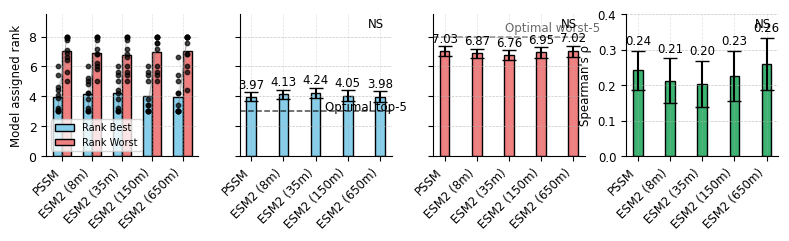

Figure saved to refined_figures/figure_screen_analysis/rank_4panel.svg


In [40]:
mut_ranks_all_df = pd.DataFrame(mut_ranks_all)
mut_ranks_all_df[mut_ranks_all_df["hybrid"] == True]

from scipy.stats import f_oneway

# Run ANOVA and keep results for significance codes
def get_anova_p(variable, data_frame):
    groups = [data_frame[data_frame["model"] == model][variable].values for model in data_frame["model"].unique()]
    if any(len(g) == 0 for g in groups):
        return None
    _, p_val = f_oneway(*groups)
    return p_val

anova_pvals = {
    "ranks_best": get_anova_p("ranks_best", mut_ranks_all_df),
    "ranks_worst": get_anova_p("ranks_worst", mut_ranks_all_df),
    "empirical_vs_model_prob_spearmanr": get_anova_p("empirical_vs_model_prob_spearmanr", mut_ranks_all_df),
}
def sig_code(p):
    if p is None: return ""
    return "NS" if p > 0.05 else "*"

# Plotting
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams.update({'font.size': 8.5})

fig_width = 8
fig_height = 2
n_models = len(mut_ranks_all_df["model"].unique())
bar_width = 0.3

# Use subplots for 4 panels, 1 row, NO excessive space
fig, axes = plt.subplots(1, 4, figsize=(fig_width, fig_height), sharey=False)

# Reduce whitespace (set wspace to a small value)
plt.subplots_adjust(wspace=0.27, left=0.065, right=0.98, bottom=0.26, top=0.97)

# Common data
x_order = mut_ranks_all_df["model"].unique()
x_labels = [names_dict.get(model, model) for model in x_order]
x = np.arange(len(x_order))
color_best = "skyblue"
color_worst = "lightcoral"

# 1. --- Subplot 1: Best + Worst, points/lines ---
ax0 = axes[0]
means_best = mut_ranks_all_df.groupby("model")["ranks_best"].mean().reindex(x_order)
means_worst = mut_ranks_all_df.groupby("model")["ranks_worst"].mean().reindex(x_order)

bars_best = ax0.bar(x - bar_width/2, means_best, width=bar_width, color=color_best, edgecolor="black", label="Rank Best")
bars_worst = ax0.bar(x + bar_width/2, means_worst, width=bar_width, color=color_worst, edgecolor="black", label="Rank Worst")

for i, model in enumerate(x_order):
    model_df = mut_ranks_all_df[mut_ranks_all_df["model"] == model]
    # Best
    ax0.scatter(
        np.full(model_df.shape[0], x[i] - bar_width/2),
        model_df["ranks_best"], color="black", alpha=0.7, s=10, marker="o", zorder=4
    )
    # Worst
    ax0.scatter(
        np.full(model_df.shape[0], x[i] + bar_width/2),
        model_df["ranks_worst"], color="black", alpha=0.7, s=10, marker="o", zorder=4
    )
    for idx, row in model_df.iterrows():
        ax0.plot(
            [x[i] - bar_width/2, x[i] + bar_width/2],
            [row["ranks_best"], row["ranks_worst"]],
            color="gray", alpha=0.2, zorder=2, linewidth=0.5
        )

ax0.set_ylabel("Model assigned rank", fontsize=8.5)
ax0.set_xticks(x)
ax0.set_xticklabels(x_labels, rotation=45, ha="right", fontsize=8.5)
ax0.legend(loc="best", fontsize=7)
ax0.spines['top'].set_visible(False)
ax0.spines['right'].set_visible(False)
ax0.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.6)
ax0.xaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
ax0.set_ylim(0, 9.5)
for label in ax0.get_yticklabels():
    label.set_fontsize(9)

# 2. --- Subplot 2: Best mean ± SEM, numbers ---
ax1 = axes[1]
means_best = mut_ranks_all_df.groupby("model")["ranks_best"].mean().reindex(x_order)
sem_best = mut_ranks_all_df.groupby("model")["ranks_best"].sem().reindex(x_order)
bars1 = ax1.bar(x, means_best, yerr=sem_best, width=bar_width, color=color_best, edgecolor="black", capsize=5)
for i, (mean_val, sem_val) in enumerate(zip(means_best, sem_best)):
    ax1.text(i, mean_val + sem_val + 0.08, f"{mean_val:.2f}", ha="center", va="bottom", fontsize=8.5)

ax1.set_ylim(0, 9.5)
ax1.set_yticklabels([])
ax1.axhline(3, ls="--", c="black", lw=1.1, alpha=0.7)
ax1.text(len(x_order)-0.15, 3 - 0.13, "Optimal top-5", color="black", fontsize=8.5, ha="right", va="bottom")
ax1.set_xticks(x)
ax1.set_xticklabels(x_labels, rotation=45, ha="right", fontsize=8.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax1.xaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
ax1.set_xlabel("", fontsize=8.5)
for label in ax1.get_yticklabels():
    label.set_fontsize(8)
ax1.text(0.95, 0.98, sig_code(anova_pvals['ranks_best']), fontsize=8.5, ha="right", va="top", transform=ax1.transAxes)

# 3. --- Subplot 3: Worst mean ± SEM, numbers ---
ax2 = axes[2]
means_worst = mut_ranks_all_df.groupby("model")["ranks_worst"].mean().reindex(x_order)
sem_worst = mut_ranks_all_df.groupby("model")["ranks_worst"].sem().reindex(x_order)
bars2 = ax2.bar(x, means_worst, yerr=sem_worst, width=bar_width, color=color_worst, edgecolor="black", capsize=5)
for i, (mean_val, sem_val) in enumerate(zip(means_worst, sem_worst)):
    ax2.text(i, mean_val + sem_val + 0.08, f"{mean_val:.2f}", ha="center", va="bottom", fontsize=8.5)

ax2.set_ylim(0, 9.5)
ax2.set_yticklabels([])
ax2.axhline(8, ls="--", c="dimgrey", lw=1.1, alpha=0.75)
ax2.text(len(x_order)-0.15, 8 + 0.13, "Optimal worst-5", color="dimgrey", fontsize=8.5, ha="right", va="bottom")
ax2.set_xticks(x)
ax2.set_xticklabels(x_labels, rotation=45, ha="right", fontsize=8.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax2.xaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
ax2.set_xlabel("", fontsize=8.5)
for label in ax2.get_yticklabels():
    label.set_fontsize(8)
ax2.text(0.95, 0.98, sig_code(anova_pvals['ranks_worst']), fontsize=8.5, ha="right", va="top", transform=ax2.transAxes)

# 4. --- Subplot 4: Spearman, mean ± SEM, numbers ---
ax3 = axes[3]
means_spearmanr = mut_ranks_all_df.groupby("model")["empirical_vs_model_prob_spearmanr"].mean().reindex(x_order)
sem_spearmanr = mut_ranks_all_df.groupby("model")["empirical_vs_model_prob_spearmanr"].sem().reindex(x_order)
bars3 = ax3.bar(x, means_spearmanr, yerr=sem_spearmanr, width=bar_width, color="mediumseagreen", edgecolor="black", capsize=5)
for i, (mean_val, sem_val) in enumerate(zip(means_spearmanr, sem_spearmanr)):
    ax3.text(i, mean_val + (sem_val if mean_val > 0 else -sem_val) + 0.01 * (1 if mean_val > 0 else -1),
             f"{mean_val:.2f}", ha="center", va="bottom" if mean_val > 0 else "top", fontsize=8.5)

ax3.set_xticks(x)
ax3.set_xticklabels(x_labels, rotation=45, ha="right", fontsize=8.5)
ax3.set_ylabel("Spearman's ρ", fontsize=8.5)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax3.xaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
ax3.set_xlabel("", fontsize=8.5)
ax3.set_ylim(0, 0.4)
for label in ax3.get_yticklabels():
    label.set_fontsize(8.5)
ax3.text(0.95, 0.98, sig_code(anova_pvals['empirical_vs_model_prob_spearmanr']), fontsize=8.5, ha="right", va="top", transform=ax3.transAxes)

# Save and show
# tight_layout is not needed since we adjust wspace, left, right directly
fig_out_dir = os.path.join("refined_figures", "figure_screen_analysis")
os.makedirs(fig_out_dir, exist_ok=True)
svg_path = os.path.join(fig_out_dir, "rank_4panel.svg")

fig.savefig(svg_path, format="svg")
plt.show()
print(f"Figure saved to {svg_path}")


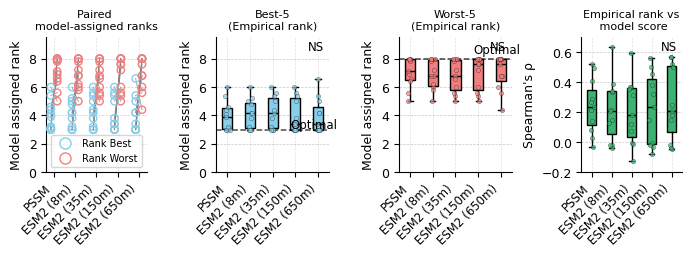

Figure saved to refined_figures/figure_screen_analysis/rank_4panel_boxplot.svg


In [41]:
mut_ranks_all_df = pd.DataFrame(mut_ranks_all)
mut_ranks_all_df[mut_ranks_all_df["hybrid"] == False]

from scipy.stats import f_oneway

# Scatter marker mapping for models (customize as needed)
# Example dictionary (replace/update as desired):
model_marker_dict = {
    "modelA": "o",
    "modelB": "s",
    "modelC": "D",
    "modelD": "^",
    "default": "o"
}
def get_marker(model):
    return model_marker_dict.get(model, model_marker_dict["default"])

# Run ANOVA and keep results for significance codes
def get_anova_p(variable, data_frame):
    groups = [data_frame[data_frame["model"] == model][variable].values for model in data_frame["model"].unique()]
    if any(len(g) == 0 for g in groups):
        return None
    _, p_val = f_oneway(*groups)
    return p_val

anova_pvals = {
    "ranks_best": get_anova_p("ranks_best", mut_ranks_all_df),
    "ranks_worst": get_anova_p("ranks_worst", mut_ranks_all_df),
    "empirical_vs_model_prob_spearmanr": get_anova_p("empirical_vs_model_prob_spearmanr", mut_ranks_all_df),
}
def sig_code(p):
    if p is None: return ""
    return "NS" if p > 0.05 else "*"

# Plotting
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams.update({'font.size': 8.5})

fig_width = 8.2
fig_height = 1.75
n_models = len(mut_ranks_all_df["model"].unique())

import matplotlib.gridspec as gridspec
fig = plt.figure(figsize=(fig_width, fig_height))
gs = gridspec.GridSpec(1, 4, width_ratios=[1, 1.13, 1.13, 1], wspace=0.65)
axes = [fig.add_subplot(gs[i]) for i in range(4)]

x_order = mut_ranks_all_df["model"].unique()
x_labels = [names_dict.get(model, model) for model in x_order]
color_best = "skyblue"
color_worst = "lightcoral"

# --- Subplot 1: Paired dots with custom markers ---
ax0 = axes[0]
positions_best = np.arange(len(x_order)) - 0.15
positions_worst = np.arange(len(x_order)) + 0.15

model_list = list(x_order)
for i, model in enumerate(model_list):
    marker = get_marker(model)
    x_b = positions_best[i]
    x_w = positions_worst[i]
    vals_best = mut_ranks_all_df.loc[mut_ranks_all_df["model"]==model, "ranks_best"].dropna()
    vals_worst = mut_ranks_all_df.loc[mut_ranks_all_df["model"]==model, "ranks_worst"].dropna()
    shared_idx = vals_best.index.intersection(vals_worst.index)
    vals_best_al = vals_best.loc[shared_idx].values
    vals_worst_al = vals_worst.loc[shared_idx].values
    ax0.scatter([x_b]*len(vals_best_al), vals_best_al, marker=marker, s=28, facecolors='none', edgecolors=color_best, linewidth=1, alpha=1, zorder=3, label=None)
    ax0.scatter([x_w]*len(vals_worst_al), vals_worst_al, marker=marker, s=28, facecolors='none', edgecolors=color_worst, linewidth=1, alpha=1, zorder=3, label=None)
    for vb, vw in zip(vals_best_al, vals_worst_al):
        ax0.plot([x_b, x_w], [vb, vw], color='gray', lw=0.7, alpha=0.7, zorder=2)

ax0.set_title("Paired \nmodel-assigned ranks", fontsize=8)
ax0.set_ylabel("Model assigned rank", fontsize=9)
ax0.set_xticks(np.arange(len(x_order)))
ax0.set_xticklabels(x_labels, rotation=45, ha="right", fontsize=8.5)
ax0.legend([plt.Line2D([0], [0], marker=model_marker_dict.get(x_order[0], "o"), color=color_best, lw=0, markerfacecolor='none', markeredgecolor=color_best, markersize=8),
            plt.Line2D([0], [0], marker=model_marker_dict.get(x_order[0], "o"), color=color_worst, lw=0, markerfacecolor='none', markeredgecolor=color_worst, markersize=8)],
           ["Rank Best", "Rank Worst"], loc="best", fontsize=7, frameon=True)
ax0.spines['top'].set_visible(False)
ax0.spines['right'].set_visible(False)
ax0.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.6)
ax0.xaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
ax0.set_ylim(0, 9.5)
for label in ax0.get_yticklabels():
    label.set_fontsize(9)

# --- Subplot 2: Best rank boxplot + custom marker scatter ---
data_best = [mut_ranks_all_df.loc[mut_ranks_all_df["model"]==model, "ranks_best"].dropna().values for model in x_order]
ax1 = axes[1]
box1 = ax1.boxplot(data_best, positions=np.arange(len(x_order)), widths=0.45, patch_artist=True,
                   boxprops=dict(facecolor=color_best, color="black"),
                   medianprops=dict(color="black"),
                   flierprops=dict(markerfacecolor=color_best, marker="o", markersize=3, alpha=0.4))
rng = np.random.default_rng(12345)
for i, (vals, model) in enumerate(zip(data_best, x_order)):
    jitter = rng.normal(loc=i, scale=0.055, size=len(vals))
    marker = get_marker(model)
    ax1.scatter(jitter, vals, marker=marker, color=color_best, s=10, alpha=0.7, edgecolor='k', linewidth=0.25, zorder=3)

ax1.set_title("Best-5\n(Empirical rank)", fontsize=8)
ax1.set_ylim(0, 9.5)
ax1.axhline(3, ls="--", c="black", lw=1.1, alpha=0.7)
ax1.text(len(x_order)-0.15, 3 - 0.13, "Optimal", color="black", fontsize=8.5, ha="right", va="bottom")
ax1.set_xticks(np.arange(len(x_order)))
ax1.set_xticklabels(x_labels, rotation=45, ha="right", fontsize=8.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax1.xaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
ax1.set_xlabel("", fontsize=8.5)
for label in ax1.get_yticklabels():
    label.set_fontsize(9)
ax1.set_ylabel("Model assigned rank", fontsize=9)
ax1.text(0.95, 0.98, sig_code(anova_pvals['ranks_best']), fontsize=8.5, ha="right", va="top", transform=ax1.transAxes)

# --- Subplot 3: Worst rank boxplot + custom marker scatter ---
data_worst = [mut_ranks_all_df.loc[mut_ranks_all_df["model"]==model, "ranks_worst"].dropna().values for model in x_order]
ax2 = axes[2]
box2 = ax2.boxplot(data_worst, positions=np.arange(len(x_order)), widths=0.45, patch_artist=True,
                   boxprops=dict(facecolor=color_worst, color="black"),
                   medianprops=dict(color="black"),
                   flierprops=dict(markerfacecolor=color_worst, marker="o", markersize=3, alpha=0.4))

for i, (vals, model) in enumerate(zip(data_worst, x_order)):
    jitter = rng.normal(loc=i, scale=0.055, size=len(vals))
    marker = get_marker(model)
    ax2.scatter(jitter, vals, marker=marker, color=color_worst, s=10, alpha=0.7, edgecolor='k', linewidth=0.25, zorder=3)

ax2.set_title("Worst-5\n(Empirical rank)", fontsize=8)
ax2.set_ylim(0, 9.5)
ax2.axhline(8, ls="--", c="black", lw=1.1, alpha=0.75)
ax2.text(len(x_order)-0.15, 8 + 0.13, "Optimal", color="black", fontsize=8.5, ha="right", va="bottom")
ax2.set_xticks(np.arange(len(x_order)))
ax2.set_xticklabels(x_labels, rotation=45, ha="right", fontsize=8.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax2.xaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
ax2.set_xlabel("", fontsize=8.5)
for label in ax2.get_yticklabels():
    label.set_fontsize(9)
ax2.set_ylabel("Model assigned rank", fontsize=9)
ax2.text(0.95, 0.98, sig_code(anova_pvals['ranks_worst']), fontsize=8.5, ha="right", va="top", transform=ax2.transAxes)

# --- Subplot 4: Spearman boxplot + custom marker scatter ---
data_spearman = [mut_ranks_all_df.loc[mut_ranks_all_df["model"]==model, "empirical_vs_model_prob_spearmanr"].dropna() for model in x_order]
ax3 = axes[3]
box3 = ax3.boxplot(data_spearman, positions=np.arange(len(x_order)), widths=0.45, patch_artist=True,
                   boxprops=dict(facecolor="mediumseagreen", color="black"),
                   medianprops=dict(color="black"),
                   flierprops=dict(markerfacecolor="mediumseagreen", marker="o", markersize=3, alpha=0.4))

for i, (vals, model) in enumerate(zip(data_spearman, x_order)):
    jitter = rng.normal(loc=i, scale=0.055, size=len(vals))
    marker = get_marker(model)
    ax3.scatter(jitter, vals, marker=marker, color="mediumseagreen", s=10, alpha=0.7, edgecolor='k', linewidth=0.25, zorder=3)

ax3.set_xticks(np.arange(len(x_order)))
ax3.set_xticklabels(x_labels, rotation=45, ha="right", fontsize=8.5)
ax3.set_ylabel("Spearman's ρ", fontsize=9)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax3.xaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.4)
ax3.set_xlabel("", fontsize=8.5)
ax3.set_ylim(-0.2, 0.7)
ax3.set_title("Empirical rank vs\n model score", fontsize=8)
for label in ax3.get_yticklabels():
    label.set_fontsize(9)
ax3.text(0.95, 0.98, sig_code(anova_pvals['empirical_vs_model_prob_spearmanr']), fontsize=8.5, ha="right", va="top", transform=ax3.transAxes)

# Save and show
fig_out_dir = os.path.join("refined_figures", "figure_screen_analysis")
os.makedirs(fig_out_dir, exist_ok=True)
svg_path = os.path.join(fig_out_dir, "rank_4panel_boxplot.svg")

fig.savefig(svg_path, format="svg")
plt.show()
print(f"Figure saved to {svg_path}")


=== ANOVA (f_oneway): Ranks Best by Model ===
F-statistic = 0.1042, p-value = 0.9805
Models: ['pssm', 'esm2_t6_8M_UR50D', 'esm2_t12_35M_UR50D', 'esm2_t30_150M_UR50D', 'esm2_t33_650M_UR50D']

=== ANOVA (f_oneway): Ranks Worst by Model ===
F-statistic = 0.1042, p-value = 0.9805
Models: ['pssm', 'esm2_t6_8M_UR50D', 'esm2_t12_35M_UR50D', 'esm2_t30_150M_UR50D', 'esm2_t33_650M_UR50D']

=== ANOVA (f_oneway): Empirical Vs Model Prob Spearmanr by Model ===
F-statistic = 0.1154, p-value = 0.9765
Models: ['pssm', 'esm2_t6_8M_UR50D', 'esm2_t12_35M_UR50D', 'esm2_t30_150M_UR50D', 'esm2_t33_650M_UR50D']



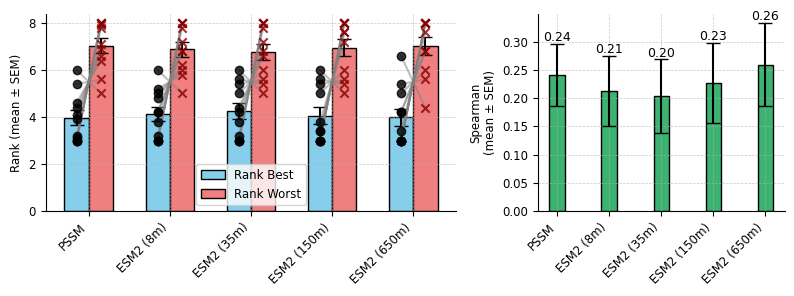

Figure saved to refined_figures/figure_screen_analysis/rank.svg


In [42]:
mut_ranks_all_df = pd.DataFrame(mut_ranks_all)
mut_ranks_all_df[mut_ranks_all_df["hybrid"] == True]

# ==== 1. Run ANOVA tests between models for each variable using scipy.stats.f_oneway ====
from scipy.stats import f_oneway

# Take the absolute value for SpearmanR for the ANOVA (if desired)
mut_ranks_all_df["empirical_vs_model_prob_spearmanr"] = mut_ranks_all_df["empirical_vs_model_prob_spearmanr"]

def print_f_oneway_anova(variable, data_frame):
    groups = []
    group_labels = data_frame["model"].unique()
    for model in group_labels:
        groups.append(data_frame[data_frame["model"] == model][variable].values)
    f_stat, p_val = f_oneway(*groups)
    print(f"=== ANOVA (f_oneway): {variable.replace('_', ' ').title()} by Model ===")
    print(f"F-statistic = {f_stat:.4f}, p-value = {p_val:.4g}")
    print(f"Models: {list(group_labels)}")
    print()

print_f_oneway_anova("ranks_best", mut_ranks_all_df)
print_f_oneway_anova("ranks_worst", mut_ranks_all_df)
print_f_oneway_anova("empirical_vs_model_prob_spearmanr", mut_ranks_all_df)

# Ensure SVG text uses font, not paths (don't convert text to outlines)
plt.rcParams['svg.fonttype'] = 'none'

fig = plt.figure(figsize=(8, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[5, 3])

ax0 = plt.subplot(gs[0])
# Make the bars thinner by reducing bar_width
bar_width = 0.3
x_order = mut_ranks_all_df["model"].unique()
x = np.arange(len(x_order))

means_best = mut_ranks_all_df.groupby("model")["ranks_best"].mean().reindex(x_order)
means_worst = mut_ranks_all_df.groupby("model")["ranks_worst"].mean().reindex(x_order)
sem_best = mut_ranks_all_df.groupby("model")["ranks_best"].sem().reindex(x_order)
sem_worst = mut_ranks_all_df.groupby("model")["ranks_worst"].sem().reindex(x_order)
x_labels = [names_dict.get(model, model) for model in x_order]

ax0.bar(x - bar_width/2, means_best, yerr=sem_best, width=bar_width, color="skyblue", edgecolor="black", label="Rank Best", capsize=5)
ax0.bar(x + bar_width/2, means_worst, yerr=sem_worst, width=bar_width, color="lightcoral", edgecolor="black", label="Rank Worst", capsize=5)

for i, model in enumerate(x_order):
    model_df = mut_ranks_all_df[mut_ranks_all_df["model"] == model]
    for _, row in model_df.iterrows():
        ax0.plot(
            [x[i] - bar_width/2, x[i] + bar_width/2],
            [row["ranks_best"], row["ranks_worst"]],
            color="gray", alpha=0.5, zorder=3
        )
        ax0.scatter(x[i] - bar_width/2, row["ranks_best"], color="black", alpha=0.8, marker="o", zorder=4)
        ax0.scatter(x[i] + bar_width/2, row["ranks_worst"], color="darkred", alpha=0.8, marker="x", zorder=4)

ax0.set_ylabel("Rank (mean ± SEM)")
ax0.set_xticks(x)
ax0.set_xticklabels(x_labels, rotation=45, ha="right")
ax0.legend()

# Remove top and right spines, and add gridlines for ax0
ax0.spines['top'].set_visible(False)
ax0.spines['right'].set_visible(False)
ax0.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax0.xaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

ax1 = plt.subplot(gs[1])
model_order = x_order
model_labels = [names_dict.get(model, model) for model in model_order]

means_spearmanr = mut_ranks_all_df.groupby("model")["empirical_vs_model_prob_spearmanr"].mean().reindex(model_order)
sem_spearmanr = mut_ranks_all_df.groupby("model")["empirical_vs_model_prob_spearmanr"].sem().reindex(model_order)
x2 = np.arange(len(model_order))

# Make these bars thinner as well by reducing width from 0.6 to 0.3
ax1.bar(x2, means_spearmanr, yerr=sem_spearmanr, width=0.3, color="mediumseagreen", edgecolor="black", capsize=5)

for i, (mean_val, sem_val) in enumerate(zip(means_spearmanr, sem_spearmanr)):
    ax1.text(i, mean_val + (sem_val if mean_val > 0 else -sem_val), f"{mean_val:.2f}", ha="center", va="bottom" if mean_val > 0 else "top", fontsize=9)
ax1.set_ylabel("Spearman\n(mean ± SEM)")
ax1.set_xticks(x2)
ax1.set_xticklabels(model_labels, rotation=45, ha="right")

# Remove top and right spines, and add gridlines for ax1
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.yaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax1.xaxis.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()

# Prepare output directory and save path
fig_out_dir = os.path.join("refined_figures", "figure_screen_analysis")
os.makedirs(fig_out_dir, exist_ok=True)
svg_path = os.path.join(fig_out_dir, "rank.svg")

fig.savefig(svg_path, format="svg")
plt.show()
print(f"Figure saved to {svg_path}")


/tmp/ipykernel_1005365/2244136191.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subset_df["short_model"] = subset_df["model"].map(lambda m: names_dict.get(m, m))
/tmp/ipykernel_1005365/2244136191.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subset_df["dataset_model"] = subset_df["dataset"] + " / " + subset_df["short_model"]
/tmp/ipykernel_1005365/2244136191.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer

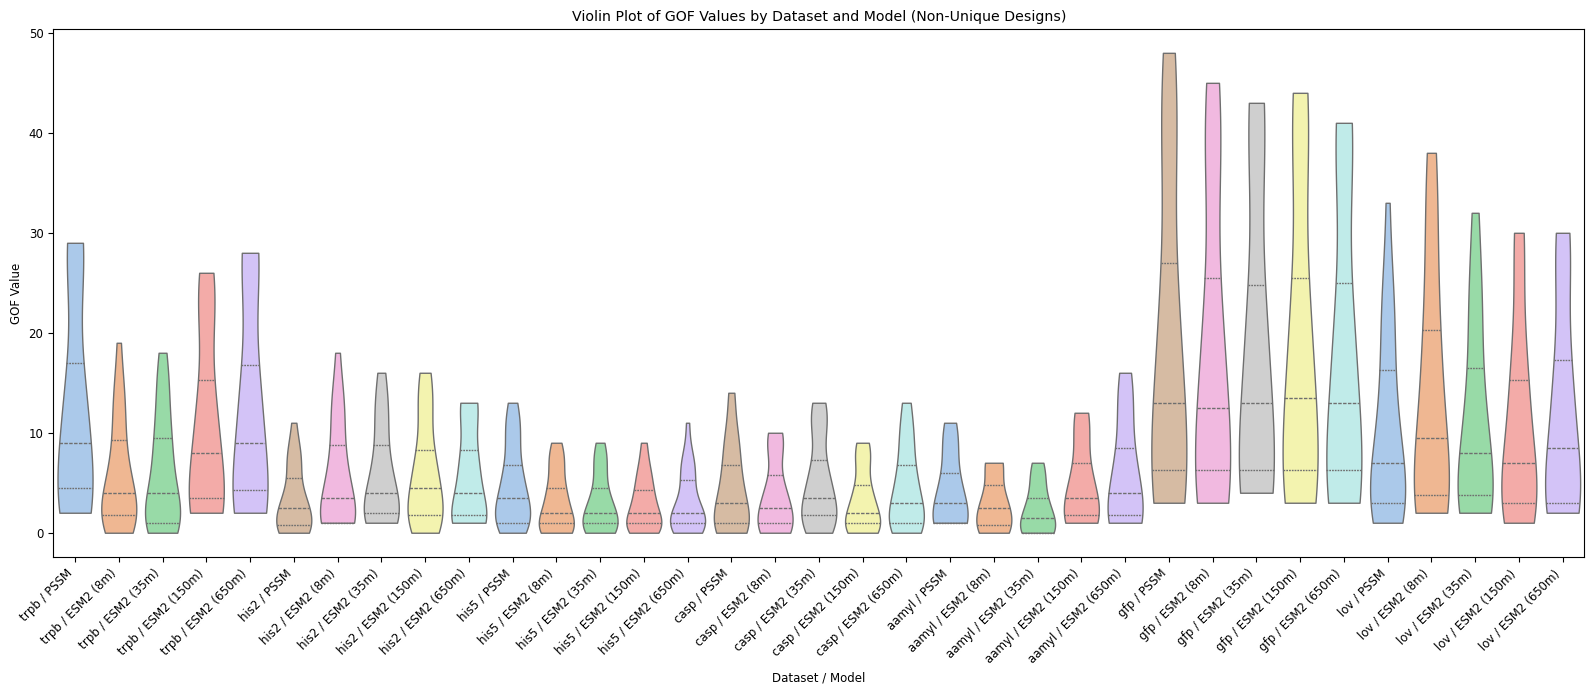

In [43]:
results_df = pd.concat(df_all)
results_df.columns

import seaborn as sns
import matplotlib.pyplot as plt

# Subset results_df for metric == "gof" and unique == False
subset_df = results_df[(results_df["metric"] == "gof") & (results_df["unique"] == True) & (results_df["normalized"] == False) & (results_df["hybrid"] == False)]

# Create a new column that combines dataset and model for grouped violin plots, using short model names from names_dict
subset_df["short_model"] = subset_df["model"].map(lambda m: names_dict.get(m, m))
subset_df["dataset_model"] = subset_df["dataset"] + " / " + subset_df["short_model"]

# Get all short model names in the order they first appear per dataset
models_per_dataset = {
    ds: subset_df[subset_df["dataset"] == ds]["short_model"].unique()
    for ds in dataset_order
}

# Create the ordered x-axis: for each dataset, append its dataset/model-shortname combinations in order
ordered_dataset_models = []
for ds in dataset_order:
    for short_model in models_per_dataset[ds]:
        ordered_dataset_models.append(f"{ds} / {short_model}")

# Make the new column categorical with our ordering
subset_df["dataset_model"] = pd.Categorical(subset_df["dataset_model"], categories=ordered_dataset_models, ordered=True)

plt.figure(figsize=(16, 7))
sns.violinplot(
    x="dataset_model",
    y="value",
    data=subset_df,
    order=ordered_dataset_models,
    cut=0,  # don't extend beyond observed data
    scale="width",  # for equal width violins
    inner="quart",  # show quartiles within the violins
    linewidth=1,
    palette="pastel"
)
plt.xlabel("Dataset / Model")
plt.ylabel("GOF Value")
plt.title("Violin Plot of GOF Values by Dataset and Model (Non-Unique Designs)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


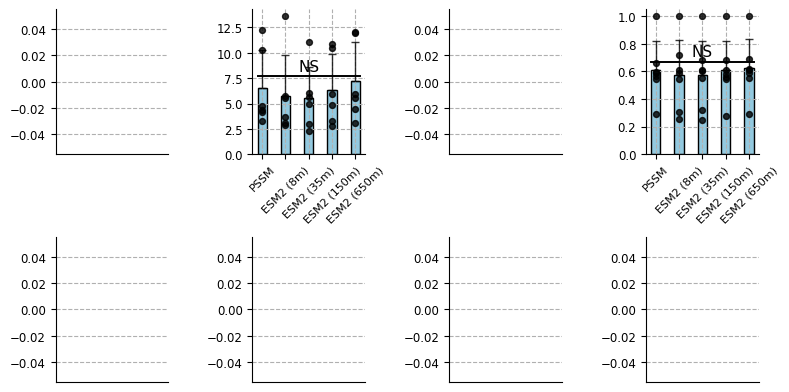

Figure saved to refined_figures/figure_screen_analysis/comparision_of_navigation_with_x_labels.svg

Friedman test and ANOVA results (per panel):
GOF (non-unique) | norm=False: Not enough data for Friedman test or ANOVA.
GOF (unique) | norm=False: Friedman test: chi2=2.86, p=5.82e-01 (NS) | ANOVA: F=0.22, p=9.26e-01 (NS)
Median Activity (non-unique) | norm=False: Not enough data for Friedman test or ANOVA.
Median Activity (unique) | norm=False: Friedman test: chi2=7.33, p=1.19e-01 (NS) | ANOVA: F=0.07, p=9.92e-01 (NS)
GOF (non-unique) | norm=True: Not enough data for Friedman test or ANOVA.
GOF (unique) | norm=True: Not enough data for Friedman test or ANOVA.
Median Activity (non-unique) | norm=True: Not enough data for Friedman test or ANOVA.
Median Activity (unique) | norm=True: Not enough data for Friedman test or ANOVA.


In [45]:

results_df = pd.concat(df_all)

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
from scipy.stats import f_oneway
import os

# For consistent order and labels
x_labels = ["PSSM", "ESM2 (8m)", "ESM2 (35m)", "ESM2 (150m)", "ESM2 (650m)"]

fig, axes = plt.subplots(2, 4, figsize=(8, 4))  # 2 rows (normalized), 4 cols (metric/unique combos)

settings_combinations = [
    ("gof", False, False, "GOF (non-unique)"),
    ("gof", True, False, "GOF (unique)"),
    ("median_activity", False, False, "Median Activity (non-unique)"),
    ("median_activity", True, False, "Median Activity (unique)")
]
test_results = []

# For each normalized row and metric/unique combo column
for norm_idx, normalized in enumerate([False, True]):
    for col_idx, (metric_to_use, unique, _, panel_title) in enumerate(settings_combinations):
        ax = axes[norm_idx, col_idx]
        # Subset data
        if metric_to_use == "gof":
            subset_df = results_df[
                (results_df["metric"] == metric_to_use) &
                (results_df["unique"] == unique) &
                (results_df["dataset"] != "gfp") &
                (results_df["normalized"] == normalized) &
                (results_df["hybrid"] == False)

            ]
        else:
            subset_df = results_df[
                (results_df["metric"] == metric_to_use) &
                (results_df["unique"] == unique) &
                (results_df["normalized"] == normalized) & 
                (results_df["hybrid"] == False)
            ]
        # For each (dataset, model), compute the median value, mean and SEM (not SD)
        grouped = subset_df.groupby(["dataset", "model"])["value"]
        stats_df = grouped.agg(
            median='median',
            mean='mean',
            sem=lambda x: np.std(x, ddof=1)/np.sqrt(len(x)) if len(x) > 1 else 0.0
        ).reset_index()
        label_to_code = {names_dict.get(model, model): model for model in stats_df["model"].unique()}
        x_order = [label_to_code[label] for label in x_labels if label in label_to_code]
        short_order = [names_dict.get(model, model) for model in x_order]

        # Barplot with even narrower width -- using the model-wide mean across all datasets
        model_means = stats_df.groupby("model")["mean"].mean().reindex(x_order)
        model_stds = stats_df.groupby("model")["mean"].std().reindex(x_order)
        # Only plot "+" error (mean + std)
        upper_err = model_stds.values
        # Remove lower error: only + std (show bar from mean up, not from mean down)
        yerr = [np.zeros_like(upper_err), upper_err]  # lower, upper

        sns.barplot(
            x=short_order,
            y=model_means.values,
            ax=ax,
            color="skyblue",
            edgecolor="black",
            width=0.4,
            errorbar=None  # No error bars from seaborn, we add "+" bars manually
        )
        # Add only "+" std error bars (asymmetric: lower error is 0)
        ax.errorbar(
            x=np.arange(len(short_order)),
            y=model_means.values,
            yerr=[np.zeros_like(upper_err), upper_err],  # asymmetric: [low, high]
            fmt='none',
            ecolor='black',
            elinewidth=1.0,
            capsize=3,
            capthick=1.0,
            alpha=0.8
        )
        # Overlay scatter per dataset, in black color, and NO error bars
        for i, model in enumerate(x_order):
            # Collect all dataset means for this model
            dataset_means = stats_df[stats_df["model"] == model]["mean"].values
            ax.scatter(
                [i] * len(dataset_means),
                dataset_means,
                color="black",
                s=18,
                alpha=0.8,
                zorder=15,
                label=None
            )
        ax.set_xticks(range(len(short_order)))
        ax.set_xticklabels(short_order, rotation=45, fontsize=8)
        ax.set_xlabel("")
        ax.grid(True, axis='y', linestyle='--')
        ax.grid(True, axis='x', linestyle='--')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        # Y-labels leftmost and col==2 for clarity
        if col_idx == 0:
            ylabel = "GOF" if metric_to_use=="gof" else "Median Activity"
            ax.set_ylabel("")
        elif col_idx == 2:
            ylabel = "GOF" if metric_to_use=="gof" else "Median Activity"
            ax.set_ylabel("")
        else:
            ax.set_ylabel("")
        # Statistics (keep)
        data_wide = stats_df.pivot(index="dataset", columns="model", values="median")
        data_wide = data_wide.reindex(columns=x_order)
        data_wide = data_wide.dropna(axis=0)
        n_models = data_wide.shape[1]
        n_datasets = data_wide.shape[0]
        friedman_msg = None
        anova_msg = None
        friedman_pval = None
        anova_pval = None
        ns_line_plotted = False
        if n_models >= 2 and n_datasets >= 2:
            try:
                friedman_input = [data_wide.iloc[:, i].values for i in range(n_models)]
                stat_friedman, p_friedman = stats.friedmanchisquare(*friedman_input)
                friedman_pval = p_friedman
                ns_needed = False
                if p_friedman > 0.05:
                    friedman_msg = f"Friedman test: chi2={stat_friedman:.2f}, p={p_friedman:.2e} (NS)"
                    ns_needed = True
                else:
                    friedman_msg = f"Friedman test: chi2={stat_friedman:.2f}, p={p_friedman:.2e}"
            except Exception as e:
                friedman_msg = f"Friedman test could not be computed: {e}"
                ns_needed = False
            try:
                stat_anova, p_anova = f_oneway(*friedman_input)
                anova_pval = p_anova
                if p_anova > 0.05:
                    anova_msg = f"ANOVA: F={stat_anova:.2f}, p={p_anova:.2e} (NS)"
                    ns_needed = True
                else:
                    anova_msg = f"ANOVA: F={stat_anova:.2f}, p={p_anova:.2e}"
            except Exception as e:
                anova_msg = f"ANOVA could not be computed: {e}"
            msg = f"{panel_title} | norm={normalized}: {friedman_msg} | {anova_msg}"
            test_results.append(msg)
            # Draw NS annotation and horizontal line above all boxes if not significant in either test
            if ns_needed:
                # Horizontal line y location
                ymin = np.nanmax(model_means.values)
                if np.isnan(ymin):
                    ymin = 0.0
                y_ns = ymin * 1.07 if ymin > 0 else 0.05

                # Line: from leftmost bar edge to rightmost bar edge, slightly wider than bar positions
                x_left = -0.2
                x_right = len(short_order)-1+0.2
                ax.plot([x_left, x_right], [y_ns, y_ns], lw=1.4, color="black", clip_on=False, zorder=20)
                # Centered NS
                ax.text((x_left + x_right)/2, y_ns + 0.03*y_ns if y_ns != 0 else 0.03,
                        "NS", ha='center', va='bottom', color='black', fontsize=11, zorder=21)
        else:
            test_results.append(f"{panel_title} | norm={normalized}: Not enough data for Friedman test or ANOVA.")

# DO NOT show any legends
for row in axes:
    for ax in row:
        ax.legend_.remove() if hasattr(ax, 'legend_') and ax.legend_ is not None else None

plt.tight_layout()

# Prepare output directory and save figure as SVG
fig_out_dir = os.path.join("refined_figures", "figure_screen_analysis")
os.makedirs(fig_out_dir, exist_ok=True)
svg_path = os.path.join(fig_out_dir, "comparision_of_navigation_with_x_labels.svg")

fig.savefig(svg_path, format="svg")
plt.show()
print(f"Figure saved to {svg_path}")

print("\nFriedman test and ANOVA results (per panel):")
for result in test_results:
    print(result)


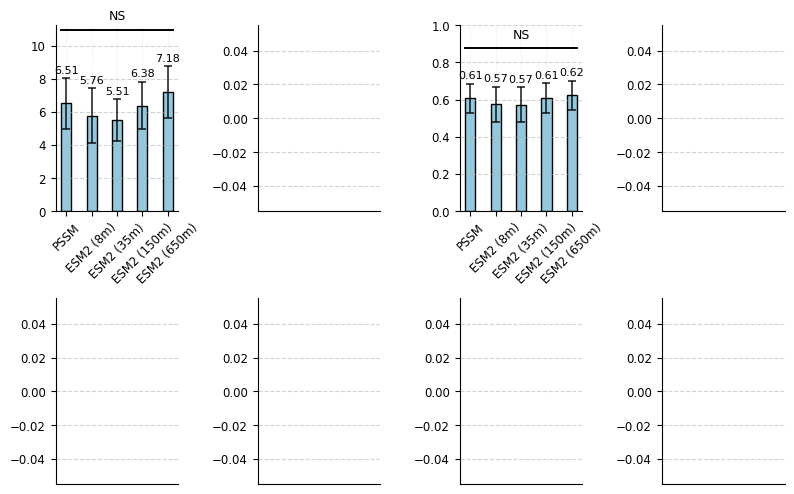

Figure saved to refined_figures/figure_screen_analysis/bar_goff_activity_unique_nonunique_ordered.svg

Friedman test and ANOVA results (per panel):
#GOF (unique) | norm=False: None | ANOVA: F=0.07, p=9.92e-01 (NS)
Normalized #GOF (unique) | norm=True: Not enough data for Friedman test or ANOVA.
Activity (unique) | norm=False: None | ANOVA: F=0.07, p=9.92e-01 (NS)
Normalized Activity (unique) | norm=True: Not enough data for Friedman test or ANOVA.
#GOF (non-unique) | norm=False: Not enough data for Friedman test or ANOVA.
Normalized #GOF (non-unique) | norm=True: Not enough data for Friedman test or ANOVA.
Activity (non-unique) | norm=False: Not enough data for Friedman test or ANOVA.
Normalized Activity (non-unique) | norm=True: Not enough data for Friedman test or ANOVA.


In [76]:

results_df = pd.concat(df_all)

# For consistent order and labels
x_labels = ["PSSM", "ESM2 (8m)", "ESM2 (35m)", "ESM2 (150m)", "ESM2 (650m)"]

# Layout: (top) 0: unique GOF, 1: unique normalized GOF, 2: unique activity, 3: unique normalized activity,
#         (bottom) 4: non-unique GOF, 5: non-unique normalized GOF, 6: non-unique activity, 7: non-unique normalized activity
panel_settings = [
    # col, row, metric, normalized, unique, panel_title
    (0, 0, "gof", False, True, "#GOF (unique)"),
    (1, 0, "gof", True, True, "Normalized #GOF (unique)"),
    (2, 0, "median_activity", False, True, "Activity (unique)"),
    (3, 0, "median_activity", True, True, "Normalized Activity (unique)"),
    (0, 1, "gof", False, False, "#GOF (non-unique)"),
    (1, 1, "gof", True, False, "Normalized #GOF (non-unique)"),
    (2, 1, "median_activity", False, False, "Activity (non-unique)"),
    (3, 1, "median_activity", True, False, "Normalized Activity (non-unique)"),
]

fig, axes = plt.subplots(2, 4, figsize=(8,5))  # order: [row, col] for y, x

test_results = []

for col, row, metric_to_use, normalized, unique, panel_title in panel_settings:
    ax = axes[row, col]
    
    # Subset data
    if metric_to_use == "gof":
        subset_df = results_df[
            (results_df["metric"] == metric_to_use) &
            (results_df["unique"] == unique) &
            (results_df["dataset"] != "gfp") &
            (results_df["normalized"] == normalized) &
            (results_df["hybrid"] == False)
        ]
    else:
        subset_df = results_df[
            (results_df["metric"] == metric_to_use) &
            (results_df["unique"] == unique) &
            (results_df["normalized"] == normalized) &
            (results_df["hybrid"] == False)
        ]
    # For each (dataset, model), compute the median value, mean and SEM (not SD)
    grouped = subset_df.groupby(["dataset", "model"])["value"]
    stats_df = grouped.agg(
        median='median',
        mean='mean',
        sem=lambda x: np.std(x, ddof=1)/np.sqrt(len(x)) if len(x) > 1 else 0.0
    ).reset_index()
    label_to_code = {names_dict.get(model, model): model for model in stats_df["model"].unique()}
    x_order = [label_to_code[label] for label in x_labels if label in label_to_code]
    short_order = [names_dict.get(model, model) for model in x_order]

    # Barplot of model-wide mean with SEM (not STD) across all datasets
    model_means = stats_df.groupby("model")["mean"].mean().reindex(x_order)
    model_sems = stats_df.groupby("model")["mean"].sem().reindex(x_order)
    yerr = model_sems.values

    sns.barplot(
        x=short_order,
        y=model_means.values,
        ax=ax,
        color="skyblue",
        edgecolor="black",
        width=0.4,
        errorbar=None  # No error bars from seaborn, we add error bars ourselves
    )

    # Add error bars: symmetric ±SEM
    ax.errorbar(
        x=np.arange(len(short_order)),
        y=model_means.values,
        yerr=yerr,
        fmt='none',
        ecolor='black',
        elinewidth=1.1,
        capsize=3,
        capthick=1.1,
        alpha=0.9,
        zorder=20
    )

    # Add value text on *top* of error bars, vertically offset above error bar
    for i, (val, sem) in enumerate(zip(model_means.values, yerr)):
        height = val + sem
        ax.text(
            i, height + 0.025 * (np.nanmax(model_means.values) if np.nanmax(model_means.values) != 0 else 1),
            f"{val:.2f}",
            ha='center', va='bottom', fontsize=8, fontweight="normal", color="black", zorder=22
        )

    ax.set_xticks(range(len(short_order)))
    ax.set_xticklabels(short_order, rotation=45, fontsize=8.5)
    ax.set_xlabel("", fontsize=8.5)
    ax.grid(True, axis='y', linestyle='--', alpha=0.55)
    ax.grid(True, axis='x', linestyle=':', alpha=0.28)  # add grid for x-axis as well
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # Set y-label font size to 8.5 as well
    ax.set_ylabel("", fontsize=8.5)

    # Statistical annotations (as before)
    data_wide = stats_df.pivot(index="dataset", columns="model", values="median")
    data_wide = data_wide.reindex(columns=x_order)
    data_wide = data_wide.dropna(axis=0)
    n_models = data_wide.shape[1]
    n_datasets = data_wide.shape[0]
    friedman_msg = None
    anova_msg = None
    friedman_pval = None
    anova_pval = None
    ns_line_plotted = False
    ylim_needs_update = False
    y_ns = None
    if n_models >= 2 and n_datasets >= 2:
        # try:
        #     friedman_input = [data_wide.iloc[:, i].values for i in range(n_models)]
        #     stat_friedman, p_friedman = stats.friedmanchisquare(*friedman_input)
        #     friedman_pval = p_friedman
        #     ns_needed = False
        #     if p_friedman > 0.05:
        #         friedman_msg = f"Friedman test: chi2={stat_friedman:.2f}, p={p_friedman:.2e} (NS)"
        #         ns_needed = True
        #     else:
        #         friedman_msg = f"Friedman test: chi2={stat_friedman:.2f}, p={p_friedman:.2e}"
        # except Exception as e:
        #     friedman_msg = f"Friedman test could not be computed: {e}"
        #     ns_needed = False
        try:
            stat_anova, p_anova = f_oneway(*friedman_input)
            anova_pval = p_anova
            if p_anova > 0.05:
                anova_msg = f"ANOVA: F={stat_anova:.2f}, p={p_anova:.2e} (NS)"
                ns_needed = True
            else:
                anova_msg = f"ANOVA: F={stat_anova:.2f}, p={p_anova:.2e}"
        except Exception as e:
            anova_msg = f"ANOVA could not be computed: {e}"
        msg = f"{panel_title} | norm={normalized}: {friedman_msg} | {anova_msg}"
        test_results.append(msg)
        # Draw NS annotation and horizontal line above all bars if NOT SIGNIFICANT in either test
        if ns_needed:
            ymin = np.nanmax(model_means.values)
            if np.isnan(ymin):
                ymin = 0.0

            # Get current ylim, extend it by 15%
            cur_ylim = ax.get_ylim()
            cur_range = cur_ylim[1] - cur_ylim[0]
            extended_ylim_top = cur_ylim[0] + cur_range * 1.22 if cur_range > 0 else 1

            y_ns = extended_ylim_top - (0.03 * cur_range if cur_range > 0 else 0.03)
            if col == 0:
                ax.set_ylim([cur_ylim[0], extended_ylim_top])
            else:
                ax.set_ylim(0,1)

            # Draw horizontal line and "NS" above the previous ylim
            x_left = -0.2
            x_right = len(short_order)-1+0.2
            ax.plot([x_left, x_right], [y_ns, y_ns], lw=1.4, color="black", clip_on=False, zorder=30)
            ax.text((x_left + x_right)/2, y_ns + (0.05 * cur_range if cur_range > 0 else 0.03),
                    "NS", ha='center', va='bottom', color='black', fontsize=9, zorder=32)
    else:
        test_results.append(f"{panel_title} | norm={normalized}: Not enough data for Friedman test or ANOVA.")

# Remove legends if present
for row in axes:
    for ax in row:
        try:
            ax.legend_.remove()
        except Exception:
            pass

plt.tight_layout()

# Prepare output directory and save figure as SVG
fig_out_dir = os.path.join("refined_figures", "figure_screen_analysis")
os.makedirs(fig_out_dir, exist_ok=True)
svg_path = os.path.join(fig_out_dir, "bar_goff_activity_unique_nonunique_ordered.svg")
fig.savefig(svg_path, format="svg")
plt.show()
print(f"Figure saved to {svg_path}")

print("\nFriedman test and ANOVA results (per panel):")
for result in test_results:
    print(result)



In [18]:




unique = True
metric = "activity"
prefix = "unique" if unique else "non_unique"

dataset_to_use = "pard3"

settings = sample_settings[dataset_to_use]["space_sizes"]
k_values = sample_settings[dataset_to_use]["k_values"]


dataset_path = DATASET_PATHS[dataset_to_use]
df = pd.read_csv(dataset_path)


# get one-hot encoding for relevant columns
relevant_columns = get_relevant_columns(dataset_to_use, df)
ohe = get_one_hot_encoding(df, relevant_columns)
ohe_columns = ohe.columns
ohe = ohe.to_numpy().astype(int)
activity = df[datasets_and_activity[dataset_to_use]["activity_col"]].to_numpy()
if dataset_to_use == "gfp":
    activity = (~activity).astype(int)

gof_threshold = np.percentile(activity, 90)

for S in [4]:
    print("Asserting for ======= S=%d========" % S) 
    print(k_values)
    print(max_scores[dataset_to_use]["best_sampled_muts_%s_%s" % (prefix, metric)][S])
    print(max_scores[dataset_to_use]["worst_sampled_muts_%s_%s" % (prefix, metric)][S])
    s_idx = np.where(np.array(settings) == S)[0]
    print("GT ===")
    print(max_scores[dataset_to_use]["%s_%s_matrix" % (prefix, metric)][s_idx])
    print(max_scores[dataset_to_use]["min_%s_%s_matrix" % (prefix, metric)][s_idx])
    print(max_scores[dataset_to_use]["%s_%s_matrix" % (prefix, metric)][s_idx]/max_scores[dataset_to_use]["min_%s_%s_matrix" % (prefix, metric)][s_idx])
    print("GT ===")
    good_indices = np.argsort( -ohe[:, max_scores[dataset_to_use]["best_sampled_muts_%s_%s" % (prefix, metric)][S]].sum(axis=1))
    bad_indices = np.argsort( -ohe[:, max_scores[dataset_to_use]["worst_sampled_muts_%s_%s" % (prefix, metric)][S]].sum(axis=1))

    
    
    is_gof = activity > gof_threshold


    recreated_values = []
    for k in k_values:
        if metric == "gof":
            recreated_values.append(np.sum(is_gof[good_indices[:k]]))
        else:
            recreated_values.append(np.median(activity[good_indices[:k]]))
    print(recreated_values)


    if metric == "gof":
        assert((np.array(recreated_values) == max_scores[dataset_to_use]["%s_%s_matrix" % (prefix, metric)][s_idx]).all())
    else:
        print(np.mean(np.array(recreated_values) - max_scores[dataset_to_use]["%s_%s_matrix" % (prefix, metric)][s_idx]))
    #print(max_scores[dataset_to_use]["%s_%s_matrix" % (prefix, metric)][s_idx])

    recreated_values = []
    for k in k_values:
        if metric == "gof":
            recreated_values.append(np.sum(is_gof[bad_indices[:k]]))
        else:
            recreated_values.append(np.median(activity[bad_indices[:k]]))
    print(recreated_values)

    if metric == "gof":
        assert((np.array(recreated_values) == max_scores[dataset_to_use]["min_%s_%s_matrix" % (prefix, metric)][s_idx]).all())
    else:
        print(np.mean(np.array(recreated_values) - max_scores[dataset_to_use]["min_%s_%s_matrix" % (prefix, metric)][s_idx]))

    print("Expected results for S=%d" % S)

    print("================================================")

Asserting for ======= S=4========
[5, 10, 20, 50, 100]
[160, 99, 112, 36]
[183, 115, 52, 92]
GT ===
[[1.12448464 1.12840039 1.10248819 0.90893733 0.90893733]]
[[-0.07518776 -0.07582733 -0.04631644 -0.01152192 -0.00187581]]
[[ -14.95568718  -14.88118288  -23.80338884  -78.88764428 -484.55780526]]
GT ===
[1.1244846424582018, 1.1284003867076424, 1.1024881872624581, 0.9089373324754798, 0.9089373324754798]
0.0
[-0.0751877616153511, -0.07582733143543866, -0.04631643816995245, -0.01152192261259145, -0.0018758078450081001]
0.0
Expected results for S=4


In [19]:
model = "pssm"
dataset = dataset_to_use

ds_mdl = "%s_%s" % (dataset, model)
s=4
K=50
k_values = sample_settings[dataset]["k_values"]
sample_sizes = sample_settings[dataset]["space_sizes"]
k_idx = np.where(np.array(k_values) == K)[0]
s_idx = np.where(np.array(sample_sizes) == s)[0]
all_results[ds_mdl]["unique_chosen_indices"][5]

print(all_results[ds_mdl]["unique_median_activity_matrix"][s_idx,k_idx])
print(all_results[ds_mdl]["unique_gof_matrix"][s_idx,k_idx])

print(all_results[ds_mdl]["unique_chosen_indices"])


model = "esm2_t6_8M_UR50D"
dataset = dataset_to_use

ds_mdl = "%s_%s" % (dataset, model)
k_values = sample_settings[dataset]["k_values"]
sample_sizes = sample_settings[dataset]["space_sizes"]
k_idx = np.where(np.array(k_values) == K)[0]
s_idx = np.where(np.array(sample_sizes) == s)[0]
all_results[ds_mdl]["unique_chosen_indices"][5]

print(all_results[ds_mdl]["unique_median_activity_matrix"][s_idx,k_idx])
print(all_results[ds_mdl]["unique_gof_matrix"][s_idx,k_idx])

print(all_results[ds_mdl]["unique_chosen_indices"])

[0.87221752]
[26]
{3: array([194, 104, 143]), 4: array([194, 104, 143, 134]), 5: array([194, 104, 143, 134, 160]), 6: array([194, 104, 143, 134, 160,  22]), 7: array([194, 104, 143, 134, 160,  22,  74]), 8: array([194, 104, 143, 134, 160,  22,  74,  89]), 9: array([194, 104, 143, 134, 160,  22,  74,  89,  47]), 10: array([194, 104, 143, 134, 160,  22,  74,  89,  47,   9]), 20: array([194, 104, 143, 134, 160,  22,  74,  89,  47,   9])}
[0.7553419]
[19]
{3: array([ 89,  74, 194]), 4: array([ 89,  74, 194, 160]), 5: array([ 89,  74, 194, 160, 143]), 6: array([ 89,  74, 194, 160, 143, 104]), 7: array([ 89,  74, 194, 160, 143, 104,  22]), 8: array([ 89,  74, 194, 160, 143, 104,  22, 134]), 9: array([ 89,  74, 194, 160, 143, 104,  22, 134,  47]), 10: array([ 89,  74, 194, 160, 143, 104,  22, 134,  47,   9]), 20: array([ 89,  74, 194, 160, 143, 104,  22, 134,  47,   9])}


In [20]:
dataset_to_use = "pte"


for dataset_to_use in dataset_order:
    print("======= Optimal mutation chosen for %s =======" % dataset_to_use)
    # non_unique_mut_space_selected = max_scores[dataset_to_use]["best_sampled_muts_non_unique_gof"]
    # unique_mut_space_selected = max_scores[dataset_to_use]["best_sampled_muts_unique_gof"]
    # for k in non_unique_mut_space_selected:
    #     print("For %d mutations, the best non-unique mut space is %s" % (k, ohe_columns[non_unique_mut_space_selected[k]]))
    #     print("For %d mutations, the best unique mut space is %s" % (k, ohe_columns[unique_mut_space_selected[k]]))

    print("========Ratio between pssm and example plm========")
    print(np.median((all_results["%s_esm2_t6_8M_UR50D" % dataset_to_use]["unique_gof_matrix"] / max_scores[dataset_to_use]["unique_gof_matrix"])))
    print(np.median((all_results["%s_pssm" % dataset_to_use]["unique_gof_matrix"] / max_scores[dataset_to_use]["unique_gof_matrix"])))
    print(np.median((all_results["%s_esm2_t6_8M_UR50D" % dataset_to_use]["unique_median_activity_matrix"] / max_scores[dataset_to_use]["unique_activity_matrix"])))
    print(np.median((all_results["%s_pssm" % dataset_to_use]["unique_median_activity_matrix"] / max_scores[dataset_to_use]["unique_activity_matrix"])))


======= Optimal mutation chosen for trpb =======
========Ratio between pssm and example plm========
0.13567073170731708
0.7484177215189873
0.10224677824236988
0.23558019812565148
======= Optimal mutation chosen for aamyl =======
========Ratio between pssm and example plm========
0.21739130434782608
0.25
0.1232037691401647
0.1714190428547604
======= Optimal mutation chosen for gfp =======
========Ratio between pssm and example plm========
0.15511329755515801
0.08168587022437841
0.0
0.0
======= Optimal mutation chosen for pard3 =======
========Ratio between pssm and example plm========
0.8
0.8
0.8745062358526516
0.8755643913365011
======= Optimal mutation chosen for pte =======
========Ratio between pssm and example plm========
0.0
0.25
0.06143346034662337
0.17077616812963092
======= Optimal mutation chosen for gcn4 =======
========Ratio between pssm and example plm========
0.2426470588235294
0.3333333333333333
0.8604822733179647
0.8586947034497769
======= Optimal mutation chosen for nmt

In [21]:
max_scores[dataset_to_use]["unique_gof_matrix"]

array([[  5.,  10.,  50.,  95., 192., 454.],
       [  5.,   9.,  45.,  89., 179., 411.],
       [  5.,  10.,  50.,  91., 183., 456.],
       [  5.,   9.,  48.,  96., 186., 465.],
       [  5.,   9.,  48.,  98., 197., 458.],
       [  5.,  10.,  50., 100., 189., 441.],
       [  5.,  10.,  50., 100., 183., 400.],
       [  5.,  10.,  50.,  99., 189., 410.]])

In [22]:
all_results["%s_pssm" % dataset_to_use]["unique_median_activity_matrix"] / all_results["%s_esm2_t6_8M_UR50D" % dataset_to_use]["unique_median_activity_matrix"] 

array([[0.91285782, 0.82743601, 0.81540634, 0.81239761, 0.7892574 ,
        0.79495281],
       [0.85616749, 0.88355386, 0.77493926, 0.81773357, 0.80246416,
        0.9354997 ],
       [0.94183547, 0.91886519, 0.9438216 , 0.849989  , 0.85675397,
        0.81850902],
       [0.86400665, 0.8936578 , 0.79740289, 0.76060468, 0.78192097,
        0.81945615],
       [0.97400349, 0.91094496, 0.77330546, 0.82993803, 0.86605249,
        0.90023128],
       [0.92213817, 0.93749582, 0.87902767, 0.87151421, 0.84781008,
        0.8042092 ],
       [1.02386844, 0.95111262, 0.93994538, 0.95230085, 0.93933527,
        0.95756142],
       [0.84464177, 0.93556126, 0.9443159 , 0.92797965, 0.92929456,
        0.90249423]])

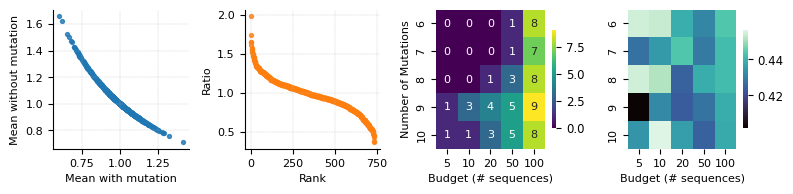

{3: array([ 13, 343, 729]),
 4: array([ 13, 343, 729, 350]),
 5: array([ 13, 343, 729, 350, 264]),
 6: array([ 13, 343, 729, 350, 264, 588]),
 7: array([ 13, 343, 729, 350, 264, 588, 523]),
 8: array([ 13, 343, 729, 350, 264, 588, 523, 574]),
 9: array([ 13, 343, 729, 350, 264, 588, 523, 574,  46]),
 10: array([ 13, 343, 729, 350, 264, 588, 523, 574,  46, 411])}

In [ ]:
 # Annotate heatmap axes: 
# Columns: Budget = [5, 10, 20, 50, 100]
# Rows: Number of mutations = [6, 7, 8, 9, 10]

dataset_path = DATASET_PATHS["gcn4"]
df = pd.read_csv(dataset_path)

# get one-hot encoding for relevant columns
relevant_columns = get_relevant_columns('gcn4', df)
ohe = get_one_hot_encoding(df, relevant_columns)
ohe_columns = ohe.columns
ohe = ohe.to_numpy().astype(int)
assert ohe.shape[1] == sum([len(pd.unique(df[C])) for C in relevant_columns])

activity_col = datasets_and_activity[dataset]["activity_col"]
activity = df[activity_col].to_numpy()

mean_with_mutation_per_column = []
mean_without_mutation_per_column = []
for i in range(ohe.shape[1]):
    mean_val_with_mutation = np.mean(activity[np.where(ohe[:, i] == 1)[0]])
    mean_val_without_mutation = np.mean(activity[np.where(ohe[:, i] == 0)[0]])
    mean_with_mutation_per_column.append(mean_val_with_mutation/mean_val_without_mutation)
    mean_without_mutation_per_column.append(mean_val_without_mutation/mean_val_with_mutation)

budget_labels = [5, 10, 20, 50, 100]
num_mutations_labels = [6, 7, 8, 9, 10]

gof_matrix = all_results["gcn4_esm2_t6_8M_UR50D"]["unique_gof_matrix"][3:,:]
activity_matrix = all_results["gcn4_esm2_t6_8M_UR50D"]["unique_median_activity_matrix"][3:,:]
activity_matrix = activity_matrix / max_dict["gcn4"]

fig, axes = plt.subplots(1, 4, figsize=(8, 2))

# First scatter plot: mean_with_mutation vs mean_without_mutation
axes[0].scatter(mean_with_mutation_per_column, mean_without_mutation_per_column, color='tab:blue', alpha=0.8, s=8)
axes[0].set_xlabel("Mean with mutation", fontsize=8)
axes[0].set_ylabel("Mean without mutation", fontsize=8)
axes[0].grid(True, which='both', linestyle='--', linewidth=0.3, alpha=0.7)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].tick_params(axis='both', labelsize=8)
# No title

# Second scatter plot: cumulative distribution of ratios
sorted_ratio = -1 * np.sort(-np.array(mean_with_mutation_per_column)/np.array(mean_without_mutation_per_column))
axes[1].scatter(np.arange(1, len(sorted_ratio)+1), sorted_ratio, color='tab:orange', alpha=0.8, s=8)
axes[1].set_xlabel("Rank", fontsize=8)
axes[1].set_ylabel("Ratio", fontsize=8)
axes[1].grid(True, which='both', linestyle='--', linewidth=0.3, alpha=0.7)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].tick_params(axis='both', labelsize=8)
# No title

# Third plot: Unique GOF matrix heatmap
sns.heatmap(
    gof_matrix,
    annot=True,
    cmap="viridis",
    ax=axes[2],
    xticklabels=budget_labels,
    yticklabels=num_mutations_labels,
    annot_kws={'fontsize': 8},
    cbar_kws={'shrink': 0.7},
    cbar=False
)
axes[2].set_xlabel("Budget (# sequences)", fontsize=8)
axes[2].set_ylabel("Number of Mutations", fontsize=8)
axes[2].tick_params(axis='both', labelsize=8)
# No title

# Fourth plot: Unique Median Activity Matrix heatmap
sns.heatmap(
    activity_matrix,
    annot=False,
    cmap="mako",
    ax=axes[3],
    xticklabels=budget_labels,
    yticklabels=num_mutations_labels,
    annot_kws={'fontsize': 8},
    cbar_kws={'shrink': 0.7},
    cbar=True
)
axes[3].set_xlabel("Budget (# sequences)", fontsize=8)
axes[3].set_ylabel("", fontsize=8)
axes[3].tick_params(axis='both', labelsize=8)
# No title

plt.tight_layout()
fig_out_dir = os.path.join("refined_figures", "figure_gof_activity_heatmaps")
os.makedirs(fig_out_dir, exist_ok=True)
svg_path = os.path.join(fig_out_dir, "joint_heatmaps_legend.svg")
fig.savefig(svg_path, format="svg")
plt.show()

all_results["gcn4_esm2_t6_8M_UR50D"]["unique_chosen_indices"]